## 1장 1강 과제

In [2]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)

df = pd.read_csv("Ames_Housing.csv")

use_cols = ["GrLivArea", "OverallQual", "YearBuilt", "SalePrice"]
data = df[use_cols].copy()

from sklearn.model_selection import train_test_split

X = data[['GrLivArea', 'OverallQual', 'YearBuilt']]
y = data['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state=42
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X_train,
    y_train,
    test_size = 0.25,
    random_state=42
)

baseline_value = y_train.mean()

y_valid_pred = [baseline_value] * len(y_valid)

---

### 테스트 데이터에서 baseline 최종 확인

### 배경

교안에서는 test 데이터를 **최종 성능을 마지막에 한 번 확인하는 데이터**라고 설명했습니다.

필수 2에서 사용한 평균 예측 baseline을 그대로 유지한 상태에서 test 데이터의 성능을 확인해보세요. 새로운 모델이나 새로운 평가 방법은 사용하지 않습니다.

### 문제

#### 요구사항

1. 필수 2에서 만든 `baseline_value`를 그대로 사용하세요.
2. test 데이터 개수만큼 동일한 값을 예측하여 `y_test_pred`를 만드세요.
3. test 데이터에 대해 `MSE`, `RMSE`, `MAE`, `R²`를 계산하세요.
4. 결과를 출력하세요.
5. 아래 질문에 답하세요.

#### Q&A

- **Q1.** 이번 과제에서 test 데이터를 사용하는 목적은 무엇인가요?
- **Q2.** test의 R²가 0에 가깝거나 음수라면 평균 예측 baseline의 성능을 어떻게 해석할 수 있나요?
- **Q3.** RMSE와 MAE 중 큰 오차에 더 큰 벌점을 주는 지표는 무엇이며, 왜 그런가요?

#### 확인 포인트

- test 데이터에서 새로운 값을 학습하거나 기준을 다시 정하지 않았는가?
- `y_train`에서 구한 baseline 값을 그대로 사용했는가?
- 교안의 회귀 평가지표 범위만 사용했는가?

In [3]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_test_pred = [baseline_value] * len(y_test)

mse = mean_squared_error(y_test, y_test_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_test_pred)
r2 = r2_score(y_test, y_test_pred)

print(f"MSE: {mse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2}")


MSE: 7676058192.02
MAE: 62516.21
RMSE: 87613.12
R²: -0.0007472934889400928


#### 과제 1 답변 작성

- **Q1. test 데이터의 목적:** 
    - baseline 모델의 성능을 평가하기 위해 사용하는 것이다.
- **Q2. R² 해석:** 
    - 0에 가까울수록 y의 평균을 전부 예측하는 것과 성능이 동일하다는 뜻이며, 음수라면 평균으로 전부 예측하는 것보다도 성능이 나쁘다는 의미이다.
- **Q3. 큰 오차에 더 큰 벌점을 주는 지표와 이유:** 
    - RMSE, 오차를 제곱해서 계산한다. 그렇기 때문에 큰 오차일수록 더 민감하게 반응하는 지표이다.

## 1장 2강 과제. Ames Housing 상황에 맞는 모델 후보 선택

---

## 배경

이번 강의의 핵심은 모델을 복잡하게 튜닝하는 것이 아니라, **데이터의 목적과 특성을 보고 어떤 모델부터 후보로 볼지 판단하는 것**입니다.

아래 상황은 모두 이번 강의에서 학습한 Linear Regression, Logistic Regression, KNN, Decision Tree, K-means, PCA의 특징만으로 판단할 수 있습니다.

## 문제

각 상황에서 가장 먼저 고려할 모델 또는 기법을 하나 선택하고, **교안에서 배운 선택 기준을 근거로 이유를 한 문장으로 작성하세요.**

### 요구사항

1. `SalePrice`처럼 연속적인 숫자를 예측하면서, 각 특성의 가중치를 확인해 예측 근거도 쉽게 설명하고 싶습니다. 어떤 모델을 먼저 고려해야 하나요?
2. 주택 특성 사이의 관계가 단순한 직선 형태가 아니며, 사람이 이해할 수 있는 `예/아니오` 규칙 형태로 나누고 싶습니다. 어떤 모델을 먼저 고려해야 하나요?
3. 거리 기반으로 주변의 비슷한 주택을 참고하여 예측하려고 합니다. 어떤 모델을 고려할 수 있으며, 사용 전에 무엇을 확인해야 하나요?
4. `SalePrice` 같은 정답 레이블을 사용하지 않고 주택을 비슷한 특성끼리 3개 그룹으로 묶고 싶습니다. 어떤 기법을 사용해야 하나요?
5. 숫자형 특성이 많아 분석하기 어렵기 때문에 핵심 정보를 유지하면서 2개의 새로운 축으로 줄이고 싶습니다. 어떤 기법을 사용해야 하나요?

### 확인 포인트

- 모델 이름만 쓰지 않고 **왜 그 모델을 선택했는지** 교안의 특성과 연결합니다.
- 성능지표 비교, 교차검증, GridSearch 등의 방법은 사용하지 않습니다.
- 과제는 필수 문제에서 학습한 **모델의 성격과 선택 기준을 다시 적용하는 수준**입니다.

### 과제 1 답변 작성

1. **연속값 예측 + 해석 중요:** 
    - 연속적인 수치인 SalePrice를 예측하면서 각 특성의 계수를 통해 특성이 예측에 미치는 영향을 확인하고 설명할 수 있기 때문에 Linear Regression을 먼저 고려한다.
2. **비선형 관계 + 규칙 해석:**  
    - Decision Tree는 특성 값을 기준으로 예/아니오 질문을 반복해 데이터를 나누기 때문에 직선이 아닌 관계도 표현할 수 있고, 분기 규칙을 사람이 그대로 읽고 이해할 수 있으므로 Decision Tree를 먼저 고려한다.
3. **가까운 이웃 기반 예측:**  
    - 주변의 가까운 데이터들을 기준으로 값을 예측하는 거리 기반 모델이므로 KNN을 고려하며, 사용 전 특성 간 스케일 차이가 거리에 영향을 주지 않도록 스케일링이 필요한지 확인해야 한다.
4. **정답 없이 3개 그룹으로 군집화:**  
    - 정답 레이블 없이 특성이 비슷한 데이터를 3개의 그룹으로 묶는 군집화가 목적이므로 K-Means를 사용하며, 거리 기반 알고리즘이므로 Feature Scaling이 필요하다.
5. **많은 특성을 2개 축으로 압축:**
    - 많은 수치형 특성의 정보를 최대한 유지하면서 더 적은 수의 새로운 축으로 차원을 축소하는 것이 목적이므로 PCA를 사용한다.

---

# 2장 1강 과제. 등록 사용자 대여량의 정상성 진단

## 배경

필수 2에서는 전체 대여량 `count`를 이용해 정상성 진단과 차분을 수행했습니다.

이번에는 같은 과정을 **등록 사용자 대여량 `registered`**에 직접 적용합니다.

> 과제는 필수 실습에서 연습한 방법을 동일하게 적용하는 수준입니다.

## 요구사항

1. `daily["registered"]`를 날짜 순서대로 선 그래프로 나타냅니다.
2. 최근 7개 값의 이동평균을 계산하여 원본 데이터와 함께 나타냅니다.
3. 원본 `registered`에 ADF Test를 수행합니다.
4. p-value를 기준으로 정상성을 판단합니다.
5. 정상성을 만족한다고 보기 어렵다면 1차 차분합니다.
6. 1차 차분을 수행한 경우, 차분 데이터에 ADF Test를 다시 수행합니다.
7. 원본과 차분 데이터의 p-value를 근거로 정상성 판단을 설명합니다. 차분하지 않았다면 그 이유를 설명합니다.
8. 진단 결과를 근거로 원본 데이터를 사용할지, 1차 차분한 데이터를 사용할지, 추가 진단이 필요한지 선택하고 이유를 설명합니다.

### 확인 포인트

- 원본 데이터의 시간 흐름을 확인했는가?
- 이동평균으로 평균 수준의 변화를 확인했는가?
- ADF Test의 p-value를 0.05와 비교했는가?
- 필요한 경우 1차 차분 후 ADF Test를 다시 수행했는가?
- 결과를 코드 출력값을 근거로 설명했는가?
- ADF 검정 결과와 그래프를 근거로 이후 모델링 방향을 선택했는가?


In [4]:
# 실습 준비 코드
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

bike = pd.read_csv("Bike_Sharing_Demand.csv")

# datetime 변환 및 시간 순서 정렬
bike["datetime"] = pd.to_datetime(bike["datetime"])
bike = bike.sort_values("datetime").reset_index(drop=True)

# 일별 시계열 준비
bike["date"] = bike["datetime"].dt.date

daily = (bike.groupby("date", as_index=False)[["count", "casual", "registered"]].sum())

daily["date"] = pd.to_datetime(daily["date"])

# 월별 시계열 준비
bike["month"] = bike["datetime"].dt.to_period("M").astype(str)

monthly = (bike.groupby("month", as_index=False)["count"].sum())

monthly["month"] = pd.to_datetime(monthly["month"])

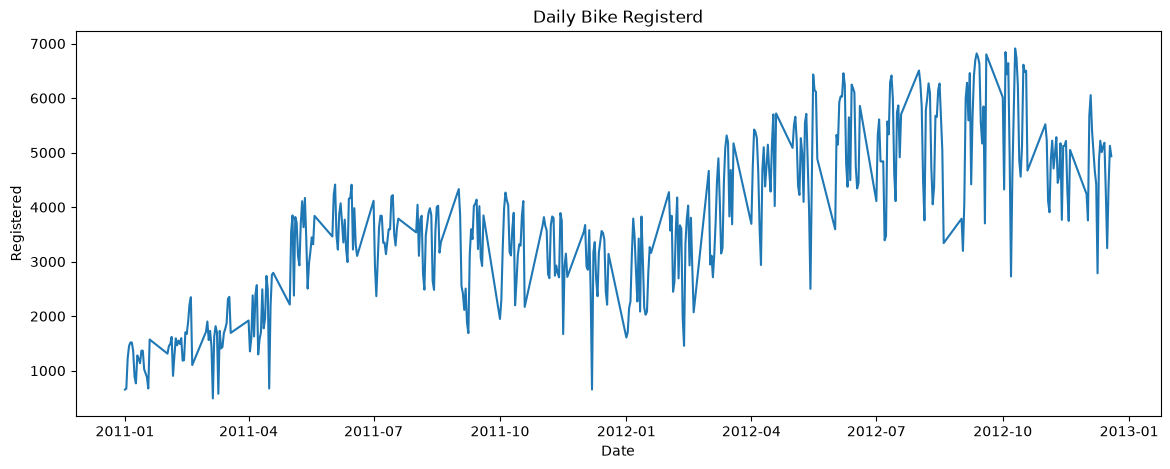

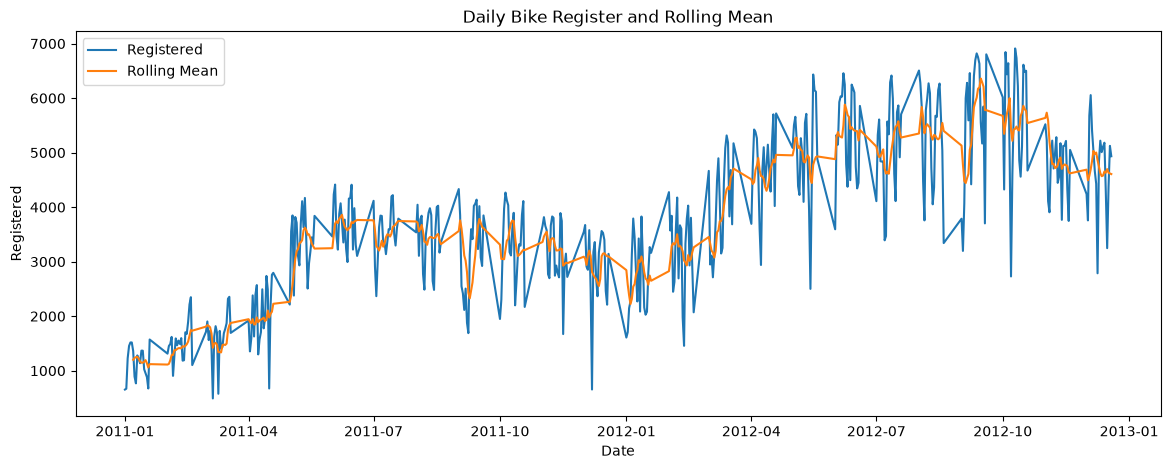

차분 전 ADF Statistic: -1.906961635000746
차분 전 p-value: 0.3287932585821237

차분 후 ADF Statistic: -6.353678332846805
차분 후 p-value: 2.5738584410443542e-08


C:\Users\yunha\AppData\Local\Temp\ipykernel_26944\2282901801.py:32: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(daily['registered'])
C:\Users\yunha\AppData\Local\Temp\ipykernel_26944\2282901801.py:42: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diff_result = adfuller(diff_daily)


In [5]:
# TODO
# 시각화 → 최근 7개 값 이동평균 → 원본 ADF Test
# → 필요 시 1차 차분 및 ADF Test 재실행 → 결과 비교
# Q1·Q2에는 출력값과 그래프를 근거로 해석과 모델링 방향을 작성하세요.

# 요구사항 1
plt.figure(figsize=(14,5))

plt.plot(daily['date'], daily['registered'])

plt.xlabel('Date')
plt.ylabel('Registered')
plt.title('Daily Bike Registerd')

plt.show()

# 요구사항 2
daily['rolling_mean'] = daily['registered'].rolling(window=7).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily['date'], daily["registered"], label="Registered")
plt.plot(daily['date'], daily["rolling_mean"], label="Rolling Mean")

plt.xlabel("Date")
plt.ylabel("Registered")
plt.title("Daily Bike Register and Rolling Mean")
plt.legend()

plt.show()

# 요구사항 3
result = adfuller(daily['registered'])

print("차분 전 ADF Statistic:", result[0])
print("차분 전 p-value:", result[1])
print()

# 요구사항 5
daily['registered_diff'] = daily['registered'].diff()
diff_daily = daily['registered_diff'].dropna()

diff_result = adfuller(diff_daily)

print("차분 후 ADF Statistic:", diff_result[0])
print("차분 후 p-value:", diff_result[1])

### Q1. 원본 등록 사용자 대여량의 ADF 검정 결과를 어떻게 해석할 수 있나요? 차분했다면 차분 전후 결과를 비교하고, 차분하지 않았다면 그 이유를 설명하세요.

**답변:**
- 차분 전 ADF 검정 결과의 p-value가 약 0.33으로 0.05보다 크기 때문에 귀무가설을 기각할 수 없다. 따라서 정상성을 만족한다고 보기 어렵다고 판단할 수 있고 이에 따라 1차 차분을 수행한다.
- 차분 후 p-value(2.57-08)는 0.05보다 작기 때문에 귀무가설을 기각한다. 즉, 차분 후에는 정상성을 만족한다고 판단한다.

### Q2. 이후 시계열 모델링에서는 원본 데이터 사용, 1차 차분 데이터 사용, 추가 진단 중 어떤 방향을 선택하겠나요? ADF 검정 결과와 그래프를 근거로 설명하세요.

**답변:**
- ADF 검정 결과 기반으로는 1차 차분 데이터를 사용하는 것을 고려하겠지만, 날짜 누락 건수가 많기 때문에 한계점은 뚜렷하게 보인다.


---

# 2장 2강 과제. 정상성 진단을 반영한 ARIMA 예측과 예측 신뢰도 평가

## 배경

필수 1의 Train/Test 분리는 유지합니다. 과제에서는 Train 데이터의 정상성을 먼저 진단한 뒤 ARIMA의 차분 차수 d를 선택하여 모델을 다시 학습합니다. MAE·RMSE와 함께 **95% 예측 구간의 하한·상한**을 실제값과 비교합니다.

## 요구사항

1. 필수 1에서 만든 `train`, `test`를 사용합니다. 정상성 진단과 모델 설정에는 Train만 사용합니다.
2. Train의 `count`와 최근 3개 관측값의 이동평균을 그래프로 확인합니다. 원본에 ADF Test를 수행하고 검정통계량과 p-value를 출력합니다. 짧은 월별 자료이므로 이번 과제의 검정 설정은 `maxlag=1, regression="c", autolag="AIC"`로 통일합니다.
3. 유의수준 0.05에서 원본의 단위근 귀무가설을 기각하면 d=0을 우선 검토합니다. 기각하지 못하면 1차 차분한 Train에 같은 설정으로 ADF Test를 다시 수행하고 차분 그래프를 확인합니다. 차분 후 기각하면 d=1을 선택합니다. 차분 후에도 기각하지 못하면 추가 진단이 필요함을 명시하고, 이번 과제에서는 d=1을 잠정 설정하여 예측 과정과 한계를 함께 평가합니다. 선택 근거에 그래프 해석도 포함합니다.
4. **차분하지 않은 Train의 원본 `count`**를 `ARIMA(order=(2, d, 1))`에 전달해 학습합니다. 차분은 모델 내부에서 처리하므로 차분 데이터에 d=1을 다시 적용하지 않습니다. 필수 2의 모델·결과와 구분하여 과제용 변수를 사용합니다.
5. `get_forecast(steps=len(test))`로 Test 기간의 예측값과 95% 예측 구간을 구합니다. `predicted_mean`과 `conf_int(alpha=0.05)`를 활용합니다.
6. Test 날짜에 맞춰 `actual`, `predicted`, `lower_95`, `upper_95`를 가진 `task_result`를 만들고 출력합니다.
7. 과제 모델의 MAE·RMSE를 계산하고 의미를 설명합니다.
8. 실제값·예측값·95% 예측 구간을 같은 그래프에 표시합니다. 시점별 구간 폭과 실제값의 구간 포함 여부를 표에 추가하고, 구간 밖인 시점을 확인합니다.
9. 실제값과 구간의 비교 및 구간 폭을 근거로 예측 신뢰도를 해석합니다. 신뢰도가 낮다고 판단한 구간의 가능한 원인 또는 모델의 한계를 한 가지 이상 설명합니다. 구간 밖인 시점이 없더라도 구간 폭과 자료의 한계를 검토합니다.

> Test는 최종 평가에만 사용합니다. Test 결과를 보고 d나 다른 모델 설정을 다시 선택하지 않습니다. 월별 값은 제공된 CSV의 관측값 합계이며, 월 전체 날짜가 없으면 완전한 월간 총수요로 해석하지 않습니다.

### 확인 포인트

- Train만으로 정상성을 진단하고 d 선택 근거를 제시했는가?
- 1차 차분 후에도 귀무가설을 기각하지 못한 경우 잠정 모델의 한계를 밝혔는가?
- 원본 Train을 모델에 입력하여 이중 차분을 피했는가?
- MAE·RMSE와 실제값·예측값·예측 구간을 함께 확인했는가?
- 구간 밖 실제값과 구간 폭을 근거로 예측 신뢰도와 한계를 설명했는가?
- Q5~Q9에 모두 답했는가?

In [6]:
# 실습 준비 코드
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

bike = pd.read_csv("Bike_Sharing_Demand.csv")

bike["datetime"] = pd.to_datetime(bike["datetime"])
bike = bike.sort_values("datetime").reset_index(drop=True)

bike["month"] = (
    bike["datetime"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly = (
    bike.groupby("month", as_index=False)["count"]
    .sum()
)

monthly = monthly.set_index("month")

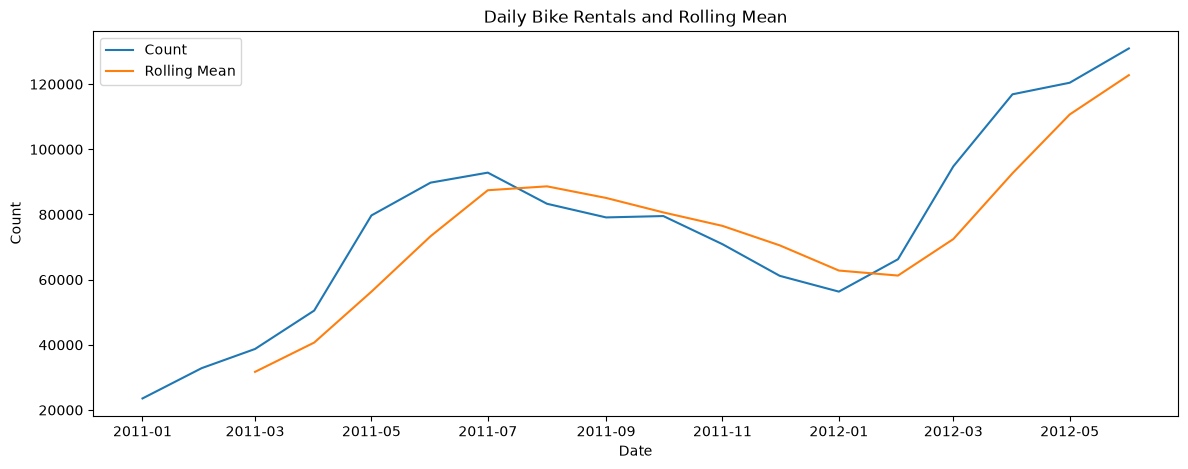

ADF Statistic: -1.571054621832968
p-value: 0.49811537706392683



C:\Users\yunha\AppData\Local\Temp\ipykernel_26944\322721521.py:24: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


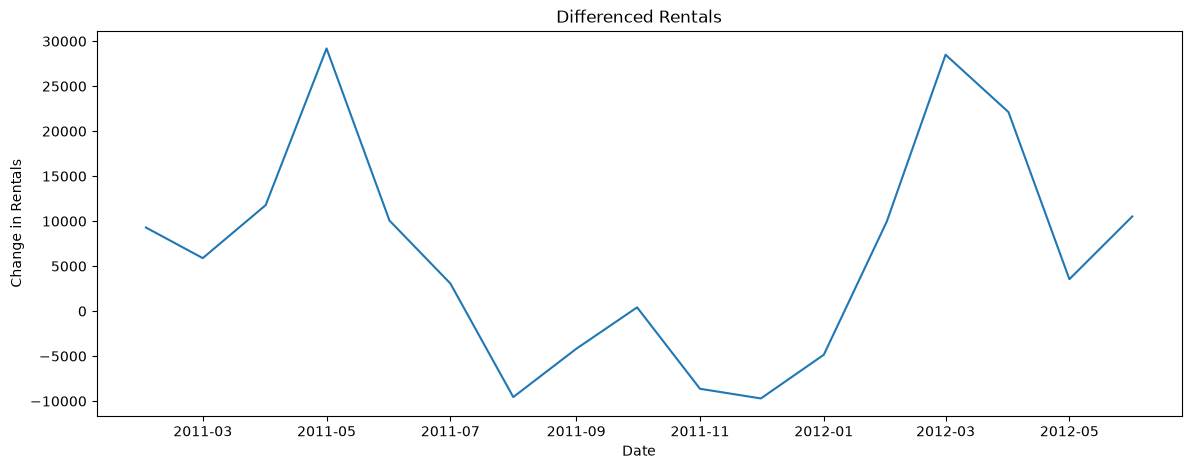

ADF Statistic: -1.9814169252766578
p-value: 0.29478009559504736



C:\Users\yunha\AppData\Local\Temp\ipykernel_26944\322721521.py:48: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diff_result = adfuller(


In [29]:
# TODO
# Train 정상성 진단 → d 선택 → 과제용 ARIMA 학습
# → 점예측·95% 예측 구간 → MAE·RMSE → 신뢰도 및 한계 해석

# 요구사항 1
# 필수 1의 Train/Test 분리
train = monthly.iloc[:-6]
test = monthly.iloc[-6:]

# 요구사항 2
train['rolling_mean'] = train['count'].rolling(window=3).mean()

plt.figure(figsize=(14, 5))
plt.plot(train.index, train["count"], label="Count")
plt.plot(train.index, train["rolling_mean"], label="Rolling Mean")

plt.xlabel("Date")
plt.ylabel("Count")
plt.title("Daily Bike Rentals and Rolling Mean")
plt.legend()

plt.show()

result = adfuller(
    train['count'],
    maxlag=1,
    regression='c',
    autolag='AIC'
)

print("ADF Statistic:", result[0])
print("p-value:", result[1])          # 0.498 -> 0.05보다 크기 때문에 귀무가설을 기각하지 못한다. 즉 정상성을 만족한다고 보기 어려워 1차 차분을 수행한다.

print()

train['count_diff'] = train['count'].diff()
diff_count = train['count_diff'].dropna()

plt.figure(figsize=(14, 5))
plt.plot(train.index, train["count_diff"])

plt.xlabel("Date")
plt.ylabel("Change in Rentals")
plt.title("Differenced Rentals")

plt.show()

diff_result = adfuller(
    diff_count,
    maxlag=1,
    regression='c',
    autolag='AIC'
)

print("ADF Statistic:", diff_result[0])
print("p-value:", diff_result[1])       # 0.298 -> 1차 차분한 후에도 0.05보다 크기 때문에 귀무가설을 기각하지 못한다. 
print()


c:\Users\yunha\KANT-study\kant-env\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\yunha\KANT-study\kant-env\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\yunha\KANT-study\kant-env\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


,actual,predicted,lower_95,upper_95,interval_width,in_interval
2012-07-01,121769,139406.0,121499.0,157313.0,35814.0,True
2012-08-01,130220,143189.0,106308.0,180069.0,73761.0,True
2012-09-01,133425,144495.0,91069.0,197920.0,106852.0,True
2012-10-01,127912,144855.0,77592.0,212119.0,134527.0,True
2012-11-01,105551,144928.0,65905.0,223951.0,158047.0,True
2012-12-01,98977,144932.0,55628.0,234237.0,178609.0,True


구간 밖 시점: []
MAE: 23991.82
RMSE: 27541.81


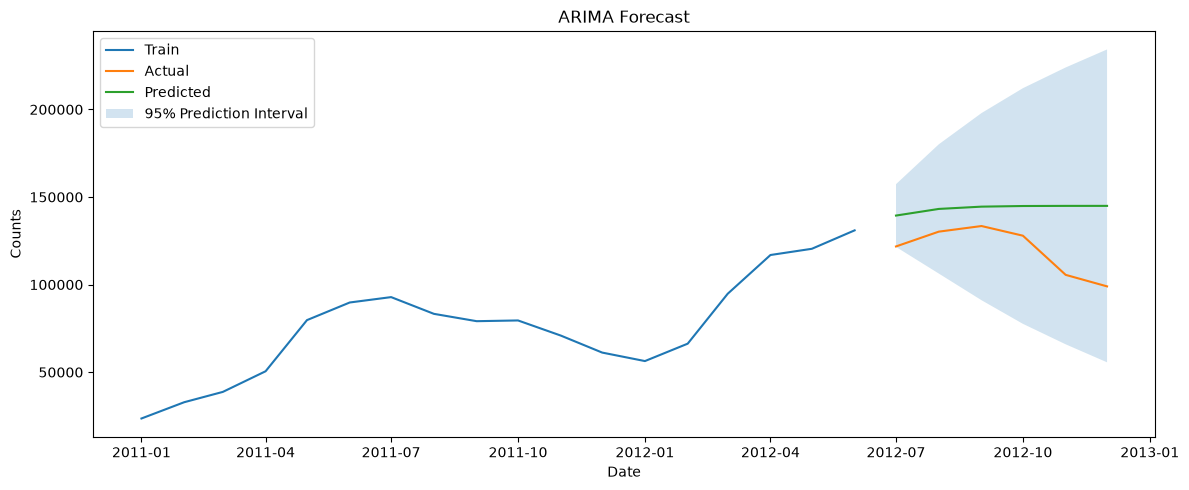

In [8]:
# 요구사항 4
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

model = ARIMA(
    train['count'],
    order=(2, 1, 1)
)

model_fit = model.fit()

# 요구사항 5
# Test 기간만큼 미래 예측
forecast_result = model_fit.get_forecast(
    steps=len(test)
)

# 예측값
predicted = forecast_result.predicted_mean

# 95% Prediction Interval
prediction_interval = forecast_result.conf_int(alpha=0.05)

# 요구사항 6
task_result = pd.DataFrame({
    "actual": test['count'],
    "predicted": predicted,
    'lower_95': prediction_interval.iloc[:, 0],
    "upper_95": prediction_interval.iloc[:, 1]
})

# 요구사항 8: 시점별 구간 폭과 구간 포함 여부
task_result["interval_width"] = task_result["upper_95"] - task_result["lower_95"]
task_result["in_interval"] = task_result["actual"].between(
    task_result["lower_95"], task_result["upper_95"]
)

# 요구사항 6: task_result 출력
display(task_result.round(0))
print("구간 밖 시점:", task_result.index[~task_result["in_interval"]].tolist())

# 요구사항 7
mae = mean_absolute_error(test['count'], predicted)
rmse = mean_squared_error(test['count'], predicted)** 0.5

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")

# 요구사항 8
plt.figure(figsize=(12, 5))

plt.plot(
    train.index,
    train["count"],
    label="Train"
)

plt.plot(
    test.index,
    test["count"],
    label="Actual"
)

plt.plot(
    task_result.index,
    task_result["predicted"],
    label="Predicted"
)

plt.fill_between(
    task_result.index,
    task_result["lower_95"],
    task_result["upper_95"],
    alpha=0.2,
    label="95% Prediction Interval"
)

plt.xlabel("Date")
plt.ylabel("Counts")
plt.title("ARIMA Forecast")
plt.legend()
plt.tight_layout()
plt.show()

### Q5. MAE는 어떻게 해석할 수 있나요?

**답변:**
- MAE는 약 23,992로, 모델의 월별 대여량 예측값이 실제 대여량과 평균적으로 약 23,992건의 절대적인 오차를 보였음을 의미한다. 이 결과는 오차의 방향은 고려하지 않았다는 것을 유의하며 해석해야 한다.

### Q6. RMSE가 MAE보다 큰 오차에 더 민감한 이유는 무엇인가요?

**답변:**
- MAE는 오차의 절댓값을 이용하여 실제값과 예측값의 평균적인 차이를 나타내는 반면, RMSE는 오차를 제곱하여 평균을 계산하기 때문에 큰 오차에 더 민감하다.

### Q7. Train 데이터의 ADF 검정 결과와 그래프를 근거로 d를 어떻게 선택했나요? 정상성 판단에 남아 있는 한계는 무엇인가요?

**답변:**
- 원본 데이터의 ADF 검정의 p-value는 약 0.498로 0.05보다 크기 때문에 단위근이 존재한다는 귀무가설을 기각하지 못하였다. 따라서 원본데이터 많으로는 정상성을 보인다고 판단할 수 없기 때문에 1차 차분을 수행하였다.
- 1차 차분 후 ADF 검정의 p-value는 약 0.295로 여전히 0.05보다 크기 때문에 귀무가설을 기각하지 못하였다. 차분 그래프에서는 값이 양수와 음수를 오가며 원본의 추세는 완화된 모습을 보이지만, 시기별로 유사한 상승 및 하락 패턴이 반복되어 정상성이 충분히 확보되었다고 보기 어렵다. 따라서 추가적인 정상성 진단이 필요하다. 

### Q8. Test 실제값이 95% 예측 구간 밖에 나타난 시점은 언제이며, 구간 폭은 시점별로 어떻게 달라지나요? 이를 근거로 예측 신뢰도를 설명하세요.

**답변:**
- Test 실제값은 모두 95% 예측구간 내에 포함되어 있어 구간 밖으로 벗어난 시점은 없다. 다만 예측 시점이 멀어질수록 95% 예측구간의 폭이 점차 넓어지는 모습을 보이며, 이는 미래 시점으로 갈수록 예측의 불확실성이 증가함을 의미한다.

### Q9. 예측 신뢰도가 낮다고 판단한 시점 또는 구간은 어디인가요? 가능한 원인이나 모델의 한계를 한 가지 이상 설명하세요.

**답변:**
- 예측 후반부로 갈수록 예측구간의 폭이 크게 넓어지므로 상대적으로 예측 신뢰도가 낮다고 판단할 수 있다. 또한 예측값은 비교적 일정하게 유지되는 반면 실제값은 후반부에 감소하는 모습을 보여 실제 변화 패턴을 충분히 반영하지 못했다. 
- 1차 차분 후에도 ADF 검정에서 정상성이 확인되지 않은 상태에서 d=1을 잠정적으로 적용했다는 점이 모델의 한계이다. 

---

# 2장 3강 과제. 시계열 데이터 예측 웹앱 완성하기

## 배경

필수 실습에서 Streamlit의 기본 화면, CSV 업로드, 월별 시계열 데이터 정리, 예측 기간 선택, ARIMA 예측까지 연습했습니다.

이번 과제에서는 앞에서 만든 기능을 하나의 `app.py`에 연결합니다.

> 새로운 기법을 추가하지 않고 필수 실습에서 사용한 기능을 연결하는 수준입니다.

## 요구사항

1. `"Bike Sharing 시계열 예측"` 제목을 표시합니다.
2. `Bike_Sharing_Demand.csv`를 업로드할 수 있도록 합니다.
3. 업로드한 데이터를 pandas DataFrame으로 불러옵니다.
4. `datetime`을 날짜/시간 자료형으로 변환합니다.
5. 시간 순서대로 정렬한 뒤 월별 `count` 합계를 계산합니다.
6. 월별 데이터를 표와 선 그래프로 표시합니다.
7. 사용자가 `1`, `3`, `6`개월 중 예측 기간을 선택합니다.
8. 전체 월별 `count`로 `ARIMA(2, 1, 1)`을 학습합니다.
9. 선택한 기간만큼 미래 값을 예측합니다.
10. 마지막 관측 월의 다음 달부터 미래 날짜를 생성합니다.
11. 미래 날짜와 예측값을 DataFrame으로 만들어 표로 표시합니다.
12. 기존 실제값과 미래 예측값을 하나의 선 그래프로 표시합니다.

### 확인 포인트

- 파일 업로드 → 데이터 처리 → 사용자 입력 → ARIMA 예측 → 결과 출력 흐름이 연결되는가?
- 미래 날짜의 개수가 사용자가 선택한 예측 기간과 같은가?
- 기존 실제값과 미래 예측값을 구분하여 표시하는가?
- 미래 실제값이 아직 없으므로 MAE와 RMSE를 계산하지 않았는가?

In [31]:
%%writefile app.py
# TODO
# 지금까지 작성한 코드를 하나의 app.py로 연결하세요.
import streamlit as st
import pandas as pd

from statsmodels.tsa.arima.model import ARIMA

st.title("Bike Sharing 시계열 예측")
st.write("월별 자전거 대여량을 확인하고 미래 값을 예측합니다.")

uploaded_file = st.file_uploader(
    "CSV 파일을 업로드하세요.",
    type=['csv']
)

if uploaded_file is not None:
    data = pd.read_csv(uploaded_file)

    st.write("원본 데이터")
    st.dataframe(data)

    data['datetime'] = pd.to_datetime(data['datetime'])
    data = data.sort_values('datetime')

    data['month'] = (data['datetime'].dt.to_period('M').dt.to_timestamp())

    monthly = (data.groupby('month', as_index=False)['count'].sum())
    monthly = monthly.set_index('month')

    st.write("월별 자전거 대여량")
    st.dataframe(monthly)
    st.write("시간에 따른 월별 대여량 변화")
    st.line_chart(monthly)

    forecast_period = st.selectbox(
        "예측 기간을 선택하세요.",
        [1, 3, 6]
    )   

    model = ARIMA(monthly['count'], order=(2, 1, 1))
    model_fit = model.fit()

    forecast = model_fit.forecast(steps=forecast_period)
    st.write("예측 결과")
    st.line_chart(forecast)

    last_month = monthly.index.max()
    future_dates = pd.date_range(
        start=last_month + pd.DateOffset(months=1),
        periods=forecast_period,
        freq='MS'   
    )

    forecast_df = pd.DataFrame(
        {'forecast': forecast.values},
        index=future_dates
    )
    forecast_df.index.name = 'month'

    st.write("미래 예측 결과")
    st.dataframe(forecast_df)

    combined = pd.concat([
        monthly.rename(columns={'count': 'actual'}),
        forecast_df
    ])

    st.write("실제값과 예측값 비교")
    st.line_chart(combined)

Overwriting app.py


### Q3. 이번 웹앱에서 MAE와 RMSE를 계산하지 않는 이유는 무엇인가요?

**답변:**  
- 미래 기간은 실제값이 아직 없어서 비교할 대상이 없으므로 MAE와 RMSE를 계산할 수 없다.

---

# 3장 1강 과제. 모델 상태를 진단하고 대응 전략 선택하기

## 배경

필수 실습에서는 학습곡선과 검증곡선을 이용해 모델의 상태를 확인했습니다.

이번 과제에서는 검증곡선 결과를 이용하여 세 가지 복잡도의 모델 상태를 직접 판단합니다.

> 과제는 필수 실습에서 확인한 결과를 해석하는 수준입니다.

## 문제

다음 세 모델을 확인하세요.

- `max_depth=1`
- `max_depth=8`
- `max_depth=None`

### 요구사항

1. 필수 2에서 만든 `gap_df`에서 세 모델의 Train score, Validation score, gap을 확인합니다.
2. 각 모델을 다음 중 하나로 진단합니다.
   - 과소적합
   - 비교적 적절한 복잡도
   - 과적합
3. 각 모델의 진단 근거를 Train score, Validation score, gap을 이용해 설명합니다.
4. 과소적합 또는 과적합 모델에 대해 교안에서 배운 대응 전략 중 적절한 방향을 하나 이상 작성합니다.

### 확인 포인트

- 점수가 낮고 gap이 작은 경우를 과소적합으로 해석할 수 있는가?
- Train score만 매우 높고 gap이 큰 경우를 과적합으로 해석할 수 있는가?
- Validation score가 높고 gap이 지나치게 크지 않은 지점을 적절한 후보로 볼 수 있는가?
- 진단 후에 대응 전략을 선택했는가?

In [10]:
# 실습 준비 코드
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import validation_curve

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "TotalBsmtSF",
    "1stFlrSF",
    "YearBuilt"
]

X = house[features]
y = house["SalePrice"]

model = DecisionTreeRegressor(random_state=42)

depth_range = [1, 2, 3, 4, 5, 8, 12, 20, None]

train_scores, validation_scores = validation_curve(
    model,
    X,
    y,
    param_name="max_depth",
    param_range=depth_range,
    cv=5,
    scoring="r2"
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

gap = train_mean - validation_mean

gap_df = pd.DataFrame({
    "max_depth": [str(d) for d in depth_range],
    "Train R2": train_mean,
    "Validation R2": validation_mean,
    "Gap": gap
})

print(gap_df)

  max_depth  Train R2  Validation R2       Gap
0         1  0.454464       0.429791  0.024674
1         2  0.634121       0.602378  0.031743
2         3  0.733594       0.679087  0.054507
3         4  0.811466       0.733510  0.077956
4         5  0.862431       0.755587  0.106844
5         8  0.948189       0.770884  0.177305
6        12  0.989787       0.746059  0.243728
7        20  0.999686       0.735295  0.264391
8      None  0.999768       0.727192  0.272575


In [11]:
# TODO
# gap_df에서 max_depth=1, 8, None에 해당하는 결과를 확인하세요.
target_df = gap_df[gap_df["max_depth"].isin(["1", "8", "None"])]
display(target_df.round(4))

,max_depth,Train R2,Validation R2,Gap
0,1,0.4545,0.4298,0.0247
5,8,0.9482,0.7709,0.1773
8,None,0.9998,0.7272,0.2726


### Q1. 세 모델의 상태를 각각 진단하세요.

| max_depth | 진단 | 근거 |
|---|---|---|
| 1 | 과소적합 | Train r2 0.45, Validation r2 0.43으로 두 점수가 모두 낮고, Gap도 0.02로 매우 작다. Train과 Validation 성능이 모두 낮아서 과소적합 가능성이 있다. |
| 8 | 비교적 적절한 복잡도 | Validation r2가 약 0.77로 후보 중 가장 높다. Gap은 0.18로 깊이 제한이 없는 모델보다 작기 때문에 비교적 적절한 복잡도를 가진 모델로 볼 수 있다. |
| None | 과적합 | Train r2는 0.99로 매우 높지만 Validation r2는 약 0.73으로 depth 8보다 낮아졌고 Gap도 약 0.27로 가장 크기 때문에 과적합 가능성이 있다. |

### Q2. 과소적합 모델과 과적합 모델에 각각 어떤 대응 전략을 사용할 수 있나요?

**답변:**  
- 과소적합 모델
    - max_depth를 늘려서 모델의 복잡도를 높인다.
    - 예측에 도움이 되는 특성을 추가한다.
- 과적합 모델
    - max_depth를 줄이거나, min_samples_leaf, min_samples_split을 늘려서 모델의 복잡도를 낮춘다.
    - 추가적인 학습 데이터를 확보한다.

---

# 3장 2강 과제. 다중공선성 진단과 Ridge / Lasso / ElasticNet 비교

## 배경

같은 Train/Test 데이터에서 세 규제 모델을 비교합니다. 성취도 평가항목에 맞춰, 비교 전에 **다중공선성의 계수 해석 영향과 VIF 진단·처치 선택**을 추가합니다.

다중공선성은 입력 특성들이 서로 강한 선형 관계를 갖는 상황입니다. VIF는 한 특성을 나머지 특성으로 설명할 때 구한 결정계수 R²를 이용해 `1 / (1 - R²)`로 계산합니다. 이때 예측 대상은 `SalePrice`가 아니라 **진단할 입력 특성 하나**이며, 보조 회귀에는 절편을 포함합니다.

## 요구사항

### A. 다중공선성 진단과 처치 방향 선택

1. **Train의 입력 특성만** 이용해 특성별 VIF를 계산하고 내림차순 표 `vif_df`를 출력합니다. 기존 `X_train_scaled`를 사용해도 됩니다. 표준화는 특성 간 선형 관계 자체를 제거하지 않습니다.
2. 이번 과제에서는 `VIF < 5`: 상대적으로 낮음, `5 ≤ VIF < 10`: 주의, `VIF ≥ 10`: 높은 수준으로 분류합니다. 이는 절대적 삭제 규칙이 아닌 실습용 판단 기준입니다.
3. 주의·높은 수준인 특성을 특성명과 VIF로 제시합니다. 없으면 없다고 작성합니다. 완전한 선형 중복으로 VIF가 무한대인 경우 높은 수준으로 해석합니다. 상수 특성의 VIF는 정의하기 어려우므로 별도로 표시합니다.
4. 다중공선성이 계수의 크기·부호·안정성과 개별 변수 해석에 미치는 영향을 설명합니다.
5. 특성의 의미와 VIF 결과를 근거로 **변수 제거·결합·규제 중 한 가지 처치 방향**을 선택하고 대상·이유·한계를 설명합니다. 높은 VIF가 없으면 불필요한 제거를 하지 않는 이유와 기존 규제 비교의 목적을 설명해도 됩니다. 제거·결합의 추가 구현은 요구하지 않습니다.

### B. 기존 규제 모델 비교

다음 설정을 그대로 사용합니다.

```python
Ridge(alpha=1.0)
Lasso(alpha=1000, max_iter=10000)
ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
```

1. 세 모델을 동일한 표준화 Train 데이터로 학습합니다.
2. 동일한 Test 데이터의 R²를 계산합니다.
3. 전체 계수 크기 `abs(coef_).sum()`과 계수가 정확히 0인 개수를 계산합니다.
4. 결과를 `comparison_df`로 정리하고, 특성별 계수를 `task_coef_df`로 출력합니다.
5. Test R²와 계수 처리 차이를 함께 설명하고 Q5~Q9에 답합니다.

> Test 점수는 지정된 세 설정의 결과를 비교·해석하는 데 사용합니다. 이 점수를 보고 변수를 제거하거나 alpha를 반복 조정하지 않습니다. 실제 모델 선택·튜닝에는 Train 내부 검증 또는 CV가 필요합니다.

### 확인 포인트

- Train 입력 특성만 사용하여 VIF를 계산했는가?
- 기준과 실제 수치를 근거로 주의할 특성을 판단했는가?
- 다중공선성의 계수 해석 영향과 처치 선택 이유를 설명했는가?
- 규제가 입력 특성의 VIF 자체를 낮추는 것은 아님을 구분했는가?
- 같은 데이터에서 세 모델의 Test R²·계수 크기·0 계수 개수를 비교했는가?


In [12]:
# 실습 준비 코드
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train 크기:", X_train_scaled.shape)
print("Test 크기:", X_test_scaled.shape)

from sklearn.linear_model import LinearRegression

alpha_values = [0.001, 0.01, 0.1, 1, 10, 100]

results = []

for alpha in alpha_values:
    model = Ridge(alpha=alpha)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    test_r2 = r2_score(y_test, y_pred)
    coef_sum = abs(model.coef_).sum()

    results.append({
        "alpha": alpha,
        "Test R2" : test_r2,
        "전체 계수 크기" : coef_sum
    })

ridge_df = pd.DataFrame(results)
print("\nRidge Regression 결과")
display(ridge_df.round(6))

lasso = Lasso(alpha=1000, max_iter=10000)
lasso.fit(X_train_scaled, y_train)

coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coef": lasso.coef_
})
print("\nLasso Regression 계수 결과")
display(coef_df)

zero_count = (lasso.coef_ == 0).sum()
print("계수가 0인 특성 개수:", zero_count)

y_pred = lasso.predict(X_test_scaled)
test_r2 = r2_score(y_test, y_pred)
print("Test R2:", test_r2)

model = ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)

model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
test_r2 = r2_score(y_test, y_pred)
print("Test R2:", test_r2)

coef_df = pd.DataFrame({
    "feature": X_train.columns,
    "coef": model.coef_
})
print("\nElasticNet Regression 계수 결과")
display(coef_df)

Train 크기: (1168, 12)
Test 크기: (292, 12)

Ridge Regression 결과


,alpha,Test R2,전체 계수 크기
0,0.001,0.799357,102172.590850
1,0.010,0.799357,102172.463666
2,0.100,0.799355,102171.096834
3,1.000,0.799331,102149.831747
4,10.000,0.799056,101725.431454
5,100.000,0.795593,97390.120153



Lasso Regression 계수 결과


,feature,coef
0,OverallQual,25520.693859
1,GrLivArea,21419.631042
2,GarageCars,6820.209072
3,GarageArea,4370.090292
4,TotalBsmtSF,7305.573442
5,1stFlrSF,3521.096689
6,2ndFlrSF,0.000000
7,FullBath,-0.000000
8,TotRmsAbvGrd,83.200163
9,YearBuilt,6966.923170


계수가 0인 특성 개수: 2
Test R2: 0.7960182963880562
Test R2: 0.7972913023796784

ElasticNet Regression 계수 결과


,feature,coef
0,OverallQual,23514.629015
1,GrLivArea,12670.768121
2,GarageCars,6785.127803
3,GarageArea,5137.437024
4,TotalBsmtSF,8016.089858
5,1stFlrSF,9237.815373
6,2ndFlrSF,6873.818086
7,FullBath,-1895.877032
8,TotRmsAbvGrd,2541.484569
9,YearBuilt,8072.285509


In [13]:
# TODO
# A. Train 특성별 VIF 계산 및 판단
vif_rows = []
X_vif = pd.DataFrame(X_train_scaled, columns=features)

for col in features:
    target = X_vif[col]
    others = X_vif.drop(columns=col)

    aux = LinearRegression()
    aux.fit(others, target)
    r2 = aux.score(others, target)

    vif = np.inf if r2 >= 1 else 1 / (1 - r2)   # 완전 중복이면 무한대
    vif_rows.append({"feature": col, "R2_aux": r2, "VIF": vif})

vif_df = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False).reset_index(drop=True)

def vif_level(v):
    if v >= 10:
        return "높은 수준"
    elif v >= 5:
        return "주의"
    else:
        return "상대적으로 낮음"

vif_df["판단"] = vif_df["VIF"].apply(vif_level)
display(vif_df.round(3))

flag_df = vif_df[vif_df["판단"] != "상대적으로 낮음"]
print("주의 · 높은 수준 특성")
display(flag_df.round(3))

# B. 기존 세 규제 모델 비교 및 특성별 계수 표 출력
models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1000, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
}

results = []
task_coef_df = pd.DataFrame({"feature": features})

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    results.append({
        "model": name,
        "Test R2": r2_score(y_test, y_pred),
        "전체 계수 크기": abs(model.coef_).sum(),
        "0 계수 개수": (model.coef_ == 0).sum()
    })

    task_coef_df[name] = model.coef_

comparison_df = pd.DataFrame(results)

print("[B-1] 세 규제 모델 비교 (comparison_df)")
display(comparison_df.round(4))

print("\n[B-2] 특성별 계수 (task_coef_df)")
display(task_coef_df.round(2))

print("\n[참고] 특성별 계수 + VIF")
display(task_coef_df.merge(vif_df[["feature", "VIF", "판단"]], on="feature").round(2))
# Q5~Q9 답변 작성


,feature,R2_aux,VIF,판단
0,GrLivArea,0.992,128.777,높은 수준
1,2ndFlrSF,0.989,91.621,높은 수준
2,1stFlrSF,0.986,73.586,높은 수준
3,GarageCars,0.811,5.291,주의
4,GarageArea,0.801,5.032,주의
5,TotalBsmtSF,0.736,3.793,상대적으로 낮음
6,TotRmsAbvGrd,0.700,3.333,상대적으로 낮음
7,OverallQual,0.628,2.689,상대적으로 낮음
8,YearBuilt,0.581,2.389,상대적으로 낮음
9,FullBath,0.552,2.234,상대적으로 낮음


주의 · 높은 수준 특성


,feature,R2_aux,VIF,판단
0,GrLivArea,0.992,128.777,높은 수준
1,2ndFlrSF,0.989,91.621,높은 수준
2,1stFlrSF,0.986,73.586,높은 수준
3,GarageCars,0.811,5.291,주의
4,GarageArea,0.801,5.032,주의


[B-1] 세 규제 모델 비교 (comparison_df)


,model,Test R2,전체 계수 크기,0 계수 개수
0,Ridge,0.7993,102149.8317,0
1,Lasso,0.7960,88648.0061,2
2,ElasticNet,0.7973,99258.8443,0



[B-2] 특성별 계수 (task_coef_df)


,feature,Ridge,Lasso,ElasticNet
0,OverallQual,25310.89,25520.69,23514.63
1,GrLivArea,13960.71,21419.63,12670.77
2,GarageCars,7041.54,6820.21,6785.13
3,GarageArea,4382.96,4370.09,5137.44
4,TotalBsmtSF,7238.59,7305.57,8016.09
5,1stFlrSF,10011.02,3521.10,9237.82
6,2ndFlrSF,7098.90,0.00,6873.82
7,FullBath,-3154.79,-0.00,-1895.88
8,TotRmsAbvGrd,1602.13,83.20,2541.48
9,YearBuilt,8343.12,6966.92,8072.29



[참고] 특성별 계수 + VIF


,feature,Ridge,Lasso,ElasticNet,VIF,판단
0,OverallQual,25310.89,25520.69,23514.63,2.69,상대적으로 낮음
1,GrLivArea,13960.71,21419.63,12670.77,128.78,높은 수준
2,GarageCars,7041.54,6820.21,6785.13,5.29,주의
3,GarageArea,4382.96,4370.09,5137.44,5.03,주의
4,TotalBsmtSF,7238.59,7305.57,8016.09,3.79,상대적으로 낮음
5,1stFlrSF,10011.02,3521.10,9237.82,73.59,높은 수준
6,2ndFlrSF,7098.90,0.00,6873.82,91.62,높은 수준
7,FullBath,-3154.79,-0.00,-1895.88,2.23,상대적으로 낮음
8,TotRmsAbvGrd,1602.13,83.20,2541.48,3.33,상대적으로 낮음
9,YearBuilt,8343.12,6966.92,8072.29,2.39,상대적으로 낮음


### Q5. Ridge와 Lasso의 가장 큰 계수 처리 차이는 무엇인가요?

**답변:**
- Ridge : 모든 계수를 0에 가깝게 줄이지만 0으로 만들지는 않는다.
- Lasso : 일부 계수를 정확히 0으로 만들어 변수 선택 효과가 있다. 위 모델에서 계수가 0이 된 특성은 2ndFlrSF, FullBath이다.
- 정보가 겹치는 특성들에 대해 Ridge는 계수를 나눠 갖게 하고, Lasso는 일부에 몰아주고 나머지를 0으로 만든다.

### Q6. 규제 모델의 성능을 비교할 때 Test R²뿐 아니라 계수도 함께 보는 이유는 무엇인가요?

**답변:**
- 세 모델의 Test R²는 0.796~0.799로 거의 같지만, 어떤 특성을 쓰고 얼마나 반영하는지는 크게 다르다. 예를 들어 Lasso는 2ndFlrSF와 FullBath를 0으로 만들었지만 Ridge는 모든 계수를 유지했다. Test R²만으로는 이런 차이를 알 수 없다.
- 계수를 확인해야 어떤 특성이 제거됐는지, 부호가 예상과 맞는지 확인할 수 있다.

### Q7. 다중공선성은 회귀계수의 크기·부호·안정성과 개별 변수의 영향 해석에 어떤 문제를 일으킬 수 있나요?

**답변:**
- 회귀계수의 크기·부호 : 상관이 높은 특성들은 서로를 대신할 수 있어서, 모델이 그 영향력을 어느 쪽에 얼마나 나눠줄지 정하기가 어렵다. 그 결과 계수가 지나치게 커지거나, 부호가 예상과 반대될 수 있다.
- 안정성 : 데이터가 조금만 바뀌어도 계수가 민감하게 반응한다.
- 개별 변수 해석 : 개별 변수의 영향을 해석하기 어려워진다.
- 다만 예측 성능은 크게 떨어지지 않을 수 있다.


### Q8. VIF 판단 기준은 무엇이며, 계산 결과에서 주의하거나 처치를 검토할 특성은 무엇인가요? 특성명과 VIF를 근거로 답하세요.

**답변:**
- 이번 과제에서는 VIF 5미만을 상대적으로 낮음, 5이상 10미만을 주의, 10 이상을 높은 수준으로 본다. 
- 높은 수준 : GrLivArea(128.78), 2ndFlrSF(91.62), 1stFlrSF(73.59). 지상 면적이 1층과 2층 면적의 합에 가까워 정보가 거의 겹친다.
- 주의 : GarageCars(5.29), GarageArea(5.03). 둘 다 차고 규모를 나타낸다.
- 나머지 7개는 VIF가 5미만이라 처치 대상이 아니다.

### Q9. VIF 결과와 특성의 의미를 고려하여 변수 제거·결합·규제 중 어떤 처치 방법을 선택하겠나요? 구체적인 대상, 선택 이유와 한계를 설명하세요.

**답변:**
- 대상: GrLivArea 제거
- 이유 : 1층 + 2층 면적과 사실상 같은 정보이기 때문에 의미상 중복이 명확하다. 
- 한계 : GrLivArea를 제거하면 전체 면적의 효과를 직접 해석할 수 없게 된다. 또한 제거 후 다중공선성이 충분히 줄어들었는지 VIF를 다시 계산해서 확인해봐야 한다.
- 참고로 규제는 계수를 안정시킬 뿐, 입력 특성 사이의 관계 자체를 바꾸지 않으므로 VIF를 낮추지는 않는다.

---

# 4장 1강 과제. 불균형 처리 전후 성능과 threshold 비교

## 배경

필수 실습에서는 기본 모델과 세 가지 불균형 처리 방법을 확인했습니다.

이번 과제에서는 **기본 Logistic Regression과 class_weight 모델**을 비교하고, class_weight 모델에서 threshold에 따른 Precision / Recall 변화를 확인합니다.

> 과제는 필수 실습에서 사용한 지표와 방법을 그대로 비교하는 수준입니다.

## 요구사항

1. 기본 Logistic Regression과 `class_weight="balanced"` 모델의 다음 지표를 하나의 DataFrame으로 정리합니다.
   - Accuracy
   - Precision
   - Recall
   - F1-score
   - PR-AUC
2. 두 모델의 Recall과 Precision 차이를 설명합니다.
3. `class_weight="balanced"` 모델의 양성 확률을 사용합니다.
4. threshold를 `0.3`, `0.5`, `0.7`로 바꾸어 예측합니다.
5. 각 threshold에서 Precision과 Recall을 계산합니다.
6. threshold 변화에 따라 두 지표가 어떻게 달라지는지 설명합니다.
7. 사기 거래를 놓치는 FN의 비용이 크다고 가정할 때, threshold를 낮추는 방향이 어떤 의미인지 설명합니다.

8. 정상 거래만 예측해도 Accuracy가 높게 나오는 이유와 이 지표만 사용할 때의 문제를 설명합니다.
9. FN의 비용과 데이터 특성을 고려해 `class_weight`, Random Undersampling, SMOTE 중 우선 적용할 방법을 하나 선택하고 이유와 한계를 설명합니다. 추가 모델 구현은 요구하지 않습니다.
10. Q4~Q7에 모두 답합니다.

> 처리 기법 선택은 근거 있는 제안으로 작성합니다. Test 결과를 보고 처리 기법이나 threshold를 반복 조정하지 않으며, 실제 설정 선택에는 Train 내부 검증 또는 교차검증이 필요합니다.

### 확인 포인트

- 불균형 처리 전후를 Accuracy 하나가 아니라 여러 지표로 비교했는가?
- threshold를 낮추면 Recall이 높아지는 경향을 설명할 수 있는가?
- threshold를 높이면 Precision이 높아지는 경향을 설명할 수 있는가?
- 단일한 정답 threshold가 있는 것이 아니라 비용 구조에 따라 결정해야 한다는 점을 이해했는가?
- 클래스 비율 때문에 Accuracy가 사기 탐지 성능을 오해하게 할 수 있음을 설명했는가?
- FN 비용과 데이터 특성을 근거로 처리 기법의 선택 이유·한계를 제시했는가?


In [14]:
# 실습 준비 코드
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# 데이터 로드
data = pd.read_csv("creditcard.csv")
print("데이터 크기:", data.shape)
display(data["Class"].value_counts(normalize=True).to_frame("ratio"))

# X / y 분리
features = [f"V{i}" for i in range(1, 29)]
X = data[features]
y = data["Class"]

# Train / Test 분리
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

# 기본 Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# class_weight="balanced" 모델
model_balanced = LogisticRegression(class_weight="balanced", max_iter=1000)
model_balanced.fit(X_train, y_train);

데이터 크기: (284807, 31)


,ratio
Class,
0,0.998273
1,0.001727


Train 크기: (227845, 28)
Test 크기: (56962, 28)


In [15]:
# TODO
# 기본 모델 / class_weight 모델 비교와 threshold 0.3, 0.5, 0.7 비교를 진행하세요.
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:,1]

y_pred_balanced = model_balanced.predict(X_test)
y_scores_balanced = model_balanced.predict_proba(X_test)[:,1]

compare_rows = []

for name, pred, score in [
    ("Logistic Regression", y_pred, y_scores),
    ("class_weight=balanced", y_pred_balanced, y_scores_balanced)
]:
    compare_rows.append({
        "model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "PR-AUC": average_precision_score(y_test, score)
    })

compare_df = pd.DataFrame(compare_rows)

print("[1] 기본 모델 vs class_weight 모델")
display(compare_df.round(4))

print("\n[기본 모델 혼동행렬]")
print(confusion_matrix(y_test, y_pred))

print("\n[class_weight 모델 혼동행렬]")
print(confusion_matrix(y_test, y_pred_balanced))

thresholds = [0.3, 0.5, 0.7]
threshold_rows = []

for th in thresholds:
    y_pred_th = (y_scores_balanced >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_th).ravel()

    threshold_rows.append({
        "threshold": th,
        "Precision": precision_score(y_test, y_pred_th),
        "Recall": recall_score(y_test, y_pred_th),
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "사기 예측 수": tp + fp
    })

threshold_df = pd.DataFrame(threshold_rows)

print("\n[2] class_weight 모델 threshold별 Precision / Recall")
display(threshold_df.round(4))

[1] 기본 모델 vs class_weight 모델


,model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Logistic Regression,0.9992,0.8289,0.6429,0.7241,0.7436
1,class_weight=balanced,0.9741,0.0579,0.9184,0.1089,0.7092



[기본 모델 혼동행렬]
[[56851    13]
 [   35    63]]

[class_weight 모델 혼동행렬]
[[55399  1465]
 [    8    90]]

[2] class_weight 모델 threshold별 Precision / Recall


,threshold,Precision,Recall,TP,FN,FP,사기 예측 수
0,0.3,0.0259,0.9184,90,8,3390,3480
1,0.5,0.0579,0.9184,90,8,1465,1555
2,0.7,0.1146,0.8980,88,10,680,768


### **요구사항 답변**
#### **1. 두 모델의 Recall과 Precision 차이**
| 모델 | Accuracy | Precision | Recall | F1-score | PR-AUC | TP | FN | FP |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 기본 Logistic Regression | 0.9992 | 0.8289 | 0.6429 | 0.7241 | 0.7436 | 63 | 35 | 13 |
| class_weight=balanced | 0.9741 | 0.0579 | 0.9184 | 0.1089 | 0.7092 | 90 | 8 | 1465 |
- Recall : 0.6429 -> 0.918로 상승. 실제 사기 98건 중 탐지 건수가 63건 -> 90건으로 27건 늘었고, 놓친 사기(FN)는 35건 -> 8건으로 줄었다.
- Precision : 0.829 -> 0.058로 크게 하락. 오탐(FP)이 13건 -> 1465건으로 늘어, 사기라고 예측한 1555건 중 실제 사기는 약 5.8%뿐이다.
- class_weight는 소수 클래스(사기)의 오류에 큰 가중치를 주기 때문에 모델이 사기를 놓치지 않는 쪽으로 학습되어 Recall은 오르고 Precision은 떨어진다.
- Accuracy만 보면 0.9992 -> 0.9741로 "성능이 나빠졌다"고 오해할 수 있지만, 사기 탐지 관점에서는 놓친 사기가 크게 줄었다.
- 반대로 F1은 0.724 -> 0.109로 낮아져 어느 지표로 보느냐에 따라 평가가 달라질 수 있다.
- PR-AUC는 0.744 -> 0.709로 큰 차이가 없다. 즉, 모델이 사기와 정상을 구분하는 능력 자체가 크게 달라진 것이 아니라, 예측 기준이 사기 쪽으로 이동한 효과에 가깝다.

#### **2. threshold의 변화에 따라 두 지표(Recall, Precision)이 어떻게 달라졌나?**
| threshold | Precision | Recall | TP | FN | FP | 사기 예측 수 |
| --- | --- | --- | --- | --- | --- | --- |
| 0.3 | 0.0259 | 0.9184 | 90 | 8 | 3390 | 3480 |
| 0.5 | 0.0579 | 0.9184 | 90 | 8 | 1465 | 1555 |
| 0.7 | 0.1146 | 0.8980 | 88 | 10 | 680 | 768 |
- threshold를 낮추면 사기로 판단하는 기준이 느슨해져 사기 예측 수가 늘어나고, Recall은 높아지거나 유지되는 대신 FP가 늘어 Precision이 낮아지는 경향이 있다.
- threshold를 높이면 확률이 높은 거래만 사기로 판단하므로 FP가 줄어 Precision이 높아지지만 놓치는 사기가 생겨 Recall이 낮아질 수 있다.
- 실제 결과
    - 0.5 -> 0.3 : Recall은 0.918로 변화 없음, FP는 1465 -> 3390건으로 1925건 증가. 남은 FN 8건은 사기 확률이 0.3보다도 낮게 나온 거래라서, threshold를 낮춰도 추가로 잡히지 않고 오탐만 늘었다.
    - 0.5 -> 0.7 : FN이 2건 늘어(Recall 0.918 -> 0.898) 대신 FP가 785건 줄어 Precision이 약 2배(0.058 -> 0.115)가 되었다.
- 따라서 threshold를 낮춘다고 Recall이 항상 비례해서 오르는 것이 아니며, 이 데이터의 경우 threshold를 0.3까지 낮추는 것이 오히려 비용을 늘리는 선택이었음을 알 수 있다.

#### **3. 사기 거래를 놓치는 FN의 비용이 크다고 가정할 때, threshold를 낮추는 방향의 의미**
- 사기를 놓쳤을 때의 피해(FN 비용)가 오탐 처리 비용(FP 비용)보다 훨씬 크다면, 오탐을 어느 정도 감수하더라도 사기를 놓치지 않는 쪽을 택하겠다는 의미이다.
- 즉 threshold를 낮추는 것은 "Precision을 희생하고 Recall을 확보하는" 비용 구조상의 선택이다.
- 하지만 위 결과처럼 Recall이 더 이상 오르지 않는 구간에서는 FP만 늘어나므로, 무조건 낮추는 것이 아니라 FN 1건과 FP 1건의 비용을 비교해 적정 지점을 정해야 한다.
- 단일한 정답 threshold는 없으며, 실제 설정은 Test 결과가 아니라 Train 내부 검증 또는 교차검증으로 결정해야 한다.


#### **4. 정상 거래만 예측해도 Accuracy가 높게 나오는 이유와 이 지표만 사용할 때의 문제**
- 하단 Q6 답변 참고

### Q4. 사기 거래를 놓치는 비용이 매우 크다면 threshold를 낮추는 방향은 어떤 장점과 단점이 있나요?

**답변:**  
- 장점 : 사기로 판단하는 기준이 낮아져 더 많은 거래를 사기로 예측하므로, 실제 사기를 놓치는 FN이 줄고 Recall이 높아질 수 있다. FN 비용이 매우 큰 상황에서는 전체 손실을 줄이는 방향이다.
- 단점 : 정상 거래를 사기로 잘못 예측하는 FP가 크게 늘어 Precision이 떨어진다. 실제로 0.5 → 0.3에서 FP가 1465건 → 3390건으로 늘었고, 이는 고객 불편(정상 결제 차단)과 검토 인력 비용 증가로 이어진다.
- 또한 이번 결과처럼 Recall이 이미 한계에 도달한 구간에서는 threshold를 낮춰도 Recall은 그대로이고 FP만 늘 수 있다.
- 따라서 FN과 FP의 비용을 함께 고려해 threshold를 정해야 하며, 그 결정은 Test가 아닌 검증 데이터나 교차검증으로 해야 한다.

### Q5. CTGAN / TVAE와 SMOTE의 가장 큰 차이를 한 문장으로 설명하세요.

**답변:**  
- SMOTE는 가까운 소수 클래스 표본 사이를 선형 보간해 새 표본을 만드는 반면, CTGAN / TVAE는 딥러닝 생성 모델(GAN / VAE)로 데이터 전체의 분포를 학습한 뒤 그 분포에서 새로운 표본을 생성한다.

### Q6. 정상 거래만 예측해도 Accuracy가 높게 나오는 이유와 이 지표만으로 사기 탐지 성능을 판단할 때의 문제를 설명하세요.

**답변:**
- 이유 : Test 데이터 56962건 중 정상 거래가 56864건(약 99.83%), 사기 거래는 98건(약 0.17%)뿐이라, 모든 거래를 정상으로 예측해도 정상 거래는 전부 맞히므로 Accuracy가 약 0.998이 된다.
- 문제:
    - 이 경우 TP = 0, Recall = 0으로 사기를 단 한 건도 탐지하지 못하는데, Accuracy만 보면 매우 좋은 모델로 오해하게 된다.
    - Accuracy는 다수 클래스의 결과에 지배되므로 모델 간 비교도 왜곡된다. class_weight 모델은 Accuracy가 0.9992 → 0.9741로 낮아졌지만, 실제로는 놓친 사기가 35건 → 8건으로 크게 줄었다.
- 따라서 불균형 데이터에서는 Precision, Recall, F1-score, PR-AUC, 혼동행렬 등을 함께 확인해야 한다.

### Q7. 사기 거래를 놓치는 FN의 비용과 데이터 특성을 고려해 class_weight·Random Undersampling·SMOTE 중 우선 적용할 방법을 하나 선택하고, 선택 이유와 한계를 설명하세요.

**답변:**
- 선택 : class_weight

- 선택 이유
    - FN 감소 효과 : 필수 2 결과에서 세 방법 모두 TP 90 / FN 8로 사기를 놓치는 건수는 같았다. FN을 줄이는 효과가 동일하다면 오탐(FP)이 가장 적은 방법이 유리하다.
    - 오탐이 가장 적음 : FP가 class_weight 1465건, SMOTE 1530건, Random Undersampling 2304건으로 class_weight가 가장 적었다.
    - 데이터 손실이 없음 : class_weight는 원본 데이터를 그대로 사용한다.
    - 인위적 표본이 없음 : SMOTE는 사기 394건 사이를 보간해 합성 표본을 만들기 때문에, 이상치 주변이나 경계가 모호한 영역에 실제와 다른 표본이 생길 수 있다. class_weight는 데이터를 바꾸지 않고 손실 함수의 가중치만 조정한다.
    - 구현이 간단 : 모델 파라미터 하나만 설정하면 되어 적용과 비교가 쉽다.

- 한계
    - Precision이 0.058로 매우 낮아, 사기 예측 1555건 중 대부분이 오탐이다. 실무에서는 검토 비용과 고객 불편이 크다.
    - PR-AUC는 SMOTE(약 0.718)가 class_weight(약 0.709)보다 약간 높았다. 차이는 작지만, 순위 성능 면에서 class_weight가 항상 가장 좋은 것은 아니다.
    - "balanced"는 클래스 비율로 자동 계산된 가중치일 뿐, 실제 FN·FP 비용을 반영한 값은 아니다.
    - 가중치와 threshold는 Test 결과로 조정하면 안 되며, Train 내부 검증 또는 교차검증(StratifiedKFold)으로 결정해야 한다. 이번 결과는 하나의 Test 분할에서 얻은 것이므로 일반화된 결론으로 보기에는 한계가 있다.

---

# 4장 2강 과제. 데이터 특성에 맞는 CV와 누수 없는 Pipeline 구성

## 배경

필수 실습에서는 불균형 분류에 적합한 StratifiedKFold와 Pipeline을 직접 사용했습니다.

이번 과제에서는 같은 Credit Card Fraud 데이터에서 **누수 없는 평가 흐름을 스스로 구성하고 설명**합니다.

> 과제는 필수 실습에서 사용한 구성 요소를 다시 연결하는 수준입니다.

## 요구사항

1. `StandardScaler()`를 사용합니다.
2. `LogisticRegression(class_weight="balanced", max_iter=1000)`을 사용합니다.
3. 두 단계를 `Pipeline`으로 연결합니다.
4. Credit Card Fraud 데이터 특성에 맞는 교차검증 방법을 직접 선택합니다.
5. `n_splits=5`를 사용합니다.
6. `cross_val_score(..., scoring="f1")`로 성능을 평가합니다.
7. Fold별 F1-score, 평균, 표준편차를 출력합니다.
8. 왜 해당 교차검증 방법을 선택했는지 설명합니다.
9. 다음 잘못된 순서를 데이터 누수 관점에서 설명합니다.

```text
전체 X로 StandardScaler.fit_transform()
        ↓
교차검증 수행
```

10. 시계열 데이터라면 같은 방법을 그대로 사용하면 안 되는 이유와 어떤 CV를 선택해야 하는지 작성합니다.

11. `build_pipeline(model)` 함수를 작성하여 `StandardScaler`와 전달받은 모델을 연결한 Pipeline을 반환합니다. 이 함수 안에서는 데이터를 학습하거나 변환하지 않습니다.
12. `evaluate_pipeline(X, y, model, cv, scoring="f1")` 함수를 작성합니다. 11번 함수를 이용해 Pipeline을 만들고 교차검증한 뒤, Fold별 점수·평균·표준편차를 반환합니다. 모델·CV·평가지표를 함수 인자로 교체할 수 있어야 합니다.
13. 12번 함수를 실제 호출하여 요구사항 7번 결과를 출력합니다. CV에서 데이터를 섞는 경우 `shuffle=True, random_state=42`를 지정하고, 모델 등 무작위성이 있는 구성 요소도 가능한 경우 `random_state=42`로 고정합니다.
14. 함수의 재사용 방법과 재현성 설정을 설명하고 Q5~Q8에 답합니다. 별도 `.py` 모듈 제작이나 다른 모델의 추가 학습은 요구하지 않습니다.

### 확인 포인트

- 불균형 분류 특성에 맞는 CV를 선택했는가?
- Pipeline이 전처리 누수를 방지하는 구조임을 설명했는가?
- 평균뿐 아니라 Fold별 점수와 표준편차도 확인했는가?
- TimeSeriesSplit의 사용 상황을 구분할 수 있는가?
- 함수 인자로 모델·CV·평가지표를 바꿀 수 있는가?
- 함수 호출로 전처리·학습·평가가 연결되고 점수가 반환되는가?
- 재현성을 위한 난수 설정을 명시했는가?


In [16]:
# 실습 준비 코드
import pandas as pd
import numpy as np

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

data = pd.read_csv("creditcard.csv")

features = [f"V{i}" for i in range(1, 29)]

X = data[features]
y = data["Class"]

In [17]:
# TODO
# build_pipeline(model)과 evaluate_pipeline(X, y, model, cv, scoring)를 작성하세요.
# 적절한 5-Fold CV와 모델을 전달하고 F1 점수·평균·표준편차를 출력하세요.

def build_pipeline(model):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

def evaluate_pipeline(X, y, model, cv, scoring='f1'):
    pipeline = build_pipeline(model)
    scores = cross_val_score(pipeline, X, y, cv=cv, scoring=scoring)
    return scores, scores.mean(), scores.std()

model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores, mean_f1, std_f1 = evaluate_pipeline(X, y, model, cv, scoring='f1')

for i, s in enumerate(scores, start=1):
    print(f"Fold {i}: F1 = {s:.4f}")
print(f"평균 F1    : {mean_f1:.4f}")
print(f"표준편차   : {std_f1:.4f}")

Fold 1: F1 = 0.1282
Fold 2: F1 = 0.1200
Fold 3: F1 = 0.1121
Fold 4: F1 = 0.1118
Fold 5: F1 = 0.1175
평균 F1    : 0.1179
표준편차   : 0.0060


### Q5. 이번 Credit Card Fraud 데이터에서 선택한 CV와 그 이유를 작성하세요.

**답변:**  
- 'StratifiedKFold(n_splits=5, shuffle=True, random_state=42)'를 선택했다. 
- 이 데이터는 사기 거래가 전체의 약 0.17%밖에 없는 극단적인 불균형 데이터이기 때문에 일반 KFold로 나누면 Fold마다 사기 샘플 수가 일정하지 않아 F1 점수가 일정하지 않고 평가가 불안정해질 수 있다. 
- StratifiedKFold는 모든 Fold에서 클래스 비율을 전체 데이터와 동일하게 유지하므로 소수 클래스를 공정하게 평가할 수 있다.
- 실제로 Fold별 F1-score가 0.1118~0.1282로 고르게 도출됐고 표준편차가 0.0060으로 작아 Fold 간 평가가 안정적이라는 것을 확인했다.

### Q6. 전체 데이터에 StandardScaler를 먼저 fit하면 어떤 정보가 Validation Fold에서 Train 쪽으로 새어 들어갈 수 있나요?

**답변:**  
- StandardScaler는 fit 단계에서 각 특성의 평균과 표준편차를 계산하는데, 전체 데이터로 먼저 fit하면 이 평균과 표준편차에 Validation Fold 데이터의 값까지 반영된다.
- 이후 Train Fold를 변환할 때 이미 Validation 데이터의 평균과 표준편차 정보가 섞인 기준을 사용하게 된다.
- 이 때문에 교차검증 점수가 실제 새로운 데이터에서의 성능보다 낙관적으로 나와 과적합이 될 수 있다.

### Q7. 작성한 함수를 다른 모델·CV·평가지표에 재사용하려면 어떤 인자를 바꾸면 되나요?

**답변:**
- evaluate_pipeline(X, y, model, cv, scoring)의 인자만 바꾸면 함수 코드를 수정하지 않고 재사용할 수 있다.
- 모델이 바뀌더라도 build_pipeline이 StandardScaler와 전달받은 모델을 자동으로 연결하므로 전처리, 학습, 평가 흐름과 누수 방지 구조가 그대로 유지된다.


### Q8. 재현성을 위해 어떤 설정을 고정했으며, Pipeline 생성 함수 안에서 전체 데이터로 전처리를 미리 학습하면 안 되는 이유는 무엇인가요?

**답변:**
- 재현성을 위해 StratifiedKFold에 shuffle=True, random_state=42를 지정해 Fold 분할을 고정했고, LogisticRegression에도 random_state=42를 지정했다.
- build_pipeline 안에서 전체 데이터로 StandardScaler를 미리 fit하면, 그 스케일러는 이미 Validation Fold를 포함한 전체 데이터의 분포 정보를 알고 있는 상태가 된다. 이 Pipeline으로 교차검증을 하면 Q6에서 설명한 데이터 누수가 발생한다.
- 따라서 build_pipeline은 Pipeline의 구조만 정의해서 반환하고, 실제 fit은 cross_val_score 내부에서 각 Fold의 Train 데이터로만 이루어지도록 해야 한다.

### (요구사항 10) 시계열 데이터인 경우
- 시계열 데이터는 시간 순서 자체가 의미를 갖는 데이터이다. StratifiedKFold처럼 데이터를 섞어서 무작위로 나누는 경우 미래 시점의 데이터로 학습하고 과거 데이터로 검증하는 경우가 발생할 수 있다.
- 이 경우 미래 정보가 학습에 새어 들어가는 시간적 누수에 해당하며 성능이 과대평가 된다.
- 시계열 데이터는 TimeSeriesSplit(n_splits=5)을 사용해야 한다. TimeSeriesSplit은 항상 과거 구간으로 학습하고 그 이후 구간으로 검증하도록 분할해서 시간 순서를 지킨다. 시간 순서를 유지해야 하므로 shuffle은 사용하지 않으며 데이터가 시간 순으로 정렬되어 있어야 한다.

---
# 5장 1강 과제. 나무 수와 예측 안정성 확인

`tree_counts = [1, 10, 50, 100]`을 사용하세요.

각 나무 수에서:
1. RandomForestRegressor 생성
2. `bootstrap=True`, `random_state=42`
3. Train 학습
4. Test R² 계산
5. DataFrame 정리
6. 나무 수에 따른 성능 변화 확인
7. 여러 예측의 평균과 분산 감소 관계 설명

In [18]:
# 실습 준비 코드
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual","GrLivArea","GarageCars","GarageArea",
    "TotalBsmtSF","1stFlrSF","2ndFlrSF","FullBath",
    "TotRmsAbvGrd","YearBuilt","YearRemodAdd","Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (1168, 12)
Test: (292, 12)


,n_estimators,test_r2
0,1,0.742870
1,10,0.883597
2,50,0.889467
3,100,0.890075


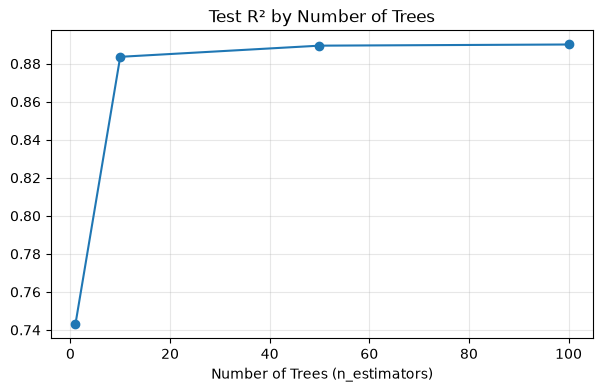

In [19]:
# TODO
tree_counts = [1, 10, 50, 100]
results = []

for n in tree_counts:
    rf_n = RandomForestRegressor(
        n_estimators=n,
        bootstrap=True,
        random_state=42
    )

    rf_n.fit(X_train, y_train)

    test_r2 = r2_score(y_test, rf_n.predict(X_test))
    results.append({"n_estimators": n, "test_r2": test_r2})

result_df = pd.DataFrame(results)
display(result_df)

plt.figure(figsize=(7, 4))
plt.plot(result_df['n_estimators'], result_df['test_r2'], marker='o')
plt.xlabel('Number of Trees (n_estimators)')
plt.title("Test R² by Number of Trees")
plt.grid(alpha=0.3)
plt.show()

### (요구사항 7) 여러 예측의 평균과 분산 감소 관계
- 랜덤 포레스트의 각 나무는 서로 다른 부트스트랩 샘플과 무작위 특성으로 학습되기 때문에, 같은 데이터라도 나무마다 예측이 조금씩 다르다. 나무 하나의 예측은 어떤 샘플을 뽑았는지에 따라 크게 달라지게 된다.(분산이 큼)
- 하지만 여러 나무의 예측을 평균을 내면 서로의 예측 오차가 상쇄되는 효과를 볼 수 있다.

### Q6. 나무 수를 늘리면 왜 예측이 더 안정적으로 변하나요?
- 각 나무는 서로 다른 부트스트랩 샘플로 학습해서 개별 예측에 오차가 있지만, 그 오차의 방향이 나무마다 다르다. 나무 수를 늘려 예측을 평균내면 개별 나무의 오차가 서로 상쇄되어 예측의 분산이 줄어들게 된다. (요구사항7)
- 실습 결과에서도 나무가 1개일 때보다(0.7429) 여러 개일 때 Test R²가 높아지고, 나무 수가 많아질수록 성능이 일정한 값에 수렴하는 것을 확인할 수 있다.

### Q7. 나무 수를 계속 늘리면 분산이 무한히 0으로 줄어드나요?
- NO. 나무들은 같은 Train 데이터에서 학습하기 때문에 서로 완전히 독립이 아닌 어느 정도 상관관계를 가지고 있다. 그래서 나무 수를 늘리면 일정 수준까지는 성능이 좋아지다가 이후에는 거의 변하지 않고 계산 비용만 늘어나게 된다. 또한 나무를 늘리는 것은 분산만 줄일 분 모델의 편향을 줄이지는 못한다.

---

# 5장 2강 과제. Early Stopping과 부스팅 모델 선택

## 배경

교안에서는 `n_estimators`를 충분히 크게 설정하고, 검증 성능이 더 이상 좋아지지 않으면 학습을 멈추는 **Early Stopping**을 소개했습니다.

이번 과제에서는 XGBoost에서 이 흐름을 적용합니다.

> 과제는 필수 실습에서 사용한 모델과 하이퍼파라미터를 그대로 활용하는 수준입니다.

## 요구사항

1. Train 데이터를 다시 Train / Validation으로 나눕니다.
2. `XGBRegressor`를 사용합니다.
3. `n_estimators=1000`
4. `learning_rate=0.05`
5. `max_depth=3`
6. `early_stopping_rounds=20`
7. Train 데이터로 학습하고 Validation 데이터를 `eval_set`으로 전달합니다.
8. Test 데이터의 RMSE를 계산합니다.
9. 실제로 사용된 나무 수를 확인합니다.
10. `n_estimators=1000`을 모두 사용하지 않고 중간에 멈췄다면 그 이유를 설명합니다.

11. Q7에서 배깅·랜덤포레스트·부스팅의 작동 원리와 편향·분산, 과적합에 미치는 영향을 비교합니다. 새로운 모델 학습 코드는 요구하지 않습니다.

### 확인 포인트

- Early Stopping이 Validation 성능을 기준으로 동작한다는 점을 이해했는가?
- 불필요하게 많은 나무를 쌓는 것을 막는 목적을 설명할 수 있는가?
- 과적합 방지와 학습 시간 절약이라는 두 가지 의미를 설명할 수 있는가?
- 배깅의 부트스트랩·예측 결합, 랜덤포레스트의 특성 무작위 선택, 부스팅의 순차적 오류 보완을 설명할 수 있는가?
- 각 방식이 편향·분산에 미치는 일반적인 영향과 과적합 가능성을 구분할 수 있는가?


In [20]:
# 실습 준비 코드
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual", "GrLivArea", "GarageCars", "GarageArea",
    "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "FullBath",
    "TotRmsAbvGrd", "YearBuilt", "YearRemodAdd", "Fireplaces",
]

X = house[features]
y = house["SalePrice"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

print("Train     :", X_tr.shape)
print("Validation:", X_val.shape)
print("Test      :", X_test.shape)

Train     : (934, 12)
Validation: (234, 12)
Test      : (292, 12)


설정한 n_estimators    : 1000
실제로 만들어진 나무 수 : 128
최적 나무 수(사용)      : 108
최적 Validation RMSE    : 27,900
Test RMSE               : 30,333
학습 시간               : 0.209s


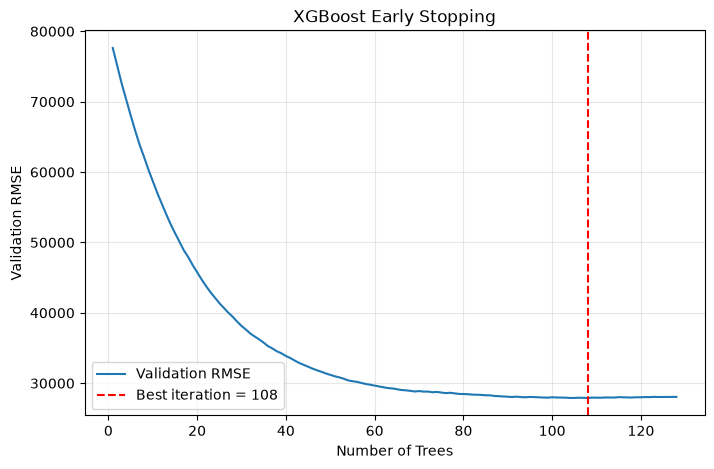

In [21]:
# TODO

xgb_es = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    early_stopping_rounds=20,
    eval_metric="rmse",
    random_state=42,
)

start = time.perf_counter()
xgb_es.fit(
    X_tr, y_tr,
    eval_set=[(X_val, y_val)],
    verbose=False,
)
train_time = time.perf_counter() - start

test_rmse = rmse(y_test, xgb_es.predict(X_test))

best_iter = xgb_es.best_iteration       
n_trees_used = best_iter + 1
n_trees_built = len(xgb_es.evals_result()["validation_0"]["rmse"])

print(f"설정한 n_estimators    : 1000")
print(f"실제로 만들어진 나무 수 : {n_trees_built}")
print(f"최적 나무 수(사용)      : {n_trees_used}")
print(f"최적 Validation RMSE    : {xgb_es.best_score:,.0f}")
print(f"Test RMSE               : {test_rmse:,.0f}")
print(f"학습 시간               : {train_time:.3f}s")

val_rmse = xgb_es.evals_result()["validation_0"]["rmse"]

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(val_rmse) + 1), val_rmse, label="Validation RMSE")
plt.axvline(n_trees_used, color="red", linestyle="--",
            label=f"Best iteration = {n_trees_used}")
plt.xlabel("Number of Trees")
plt.ylabel("Validation RMSE")
plt.title("XGBoost Early Stopping")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Q6. Early Stopping은 어떤 상황에서 학습을 멈추나요?

**답변:**  
- 학습에 쓰지 않은 Validation 데이터의 성능을 매 단계 확인하다가 정해진 횟수동안 연속으로 개선되지 않으면 학습을 멈춘다.

### Q7. 배깅·랜덤포레스트·부스팅의 작동 원리와 편향·분산에 미치는 영향을 비교하세요.

다음 항목을 포함하여 각 방법을 설명하세요.

1. **배깅:** 부트스트랩 표본을 만드는 방법과 여러 모델의 예측을 결합하는 방법, 분산 감소의 이유
2. **랜덤포레스트:** 배깅에 더해 각 노드의 분할 후보 특성을 무작위로 선택하는 이유와 트리 간 상관·분산에 미치는 영향
3. **부스팅:** 이전 모델의 오류를 순차적으로 보완하는 원리와 편향 감소의 관계, 과적합 가능성 및 이를 줄이는 방법

> 편향·분산에 대한 효과는 일반적인 경향입니다. 한 방법이 편향 또는 분산만 바꾸거나 과적합을 항상 막는다고 단정하지 마세요.

**답변:**

- 배깅: 원본 Train 데이터에서 같은 크기로 중복을 허용해 무작위 추출한 표본을 여러 개 만든다. 각 표본에서 모델을 독립적으로 학습한 뒤, 회귀는 평균으로 분류는 다수결로 예측을 결합한다. 개별 모델은 데이터가 조금만 바뀌어도 예측잉 크게 흔들리기 때문에 분산이 크다. 그렇기 때문에 서로 다른 표본으로 학습한 모델들을 평균을 내면 오차가 일부 상쇄되어 분산이 줄어드는 효과가 발생한다. 그러나 편향은 평균을 내도 크게 달라지지 않는 경향이 있다.
- 랜덤포레스트: 배깅과 각 노드를 분할할 때 전체 특성 중 일부만 무작위로 골라 후보로 사용한다. 배깅을 쓰면 강한 특성이 모든 트리의 상단 분할을 차지하기 때문에 트리들이 비슷해진다. 그렇기 때문에 트리 간 상관이 높아 평균을 내도 분산이 잘 줄어들지 않는다. 이 문제를 해결하기 위해 특성을 무작위로 제한하여 표본을 추출한 트리들이 서로 다른 구조를 갖게 되어 상관이 낮아지고, 평균으로 결합했을 때 분산 감소 효과도 커지게 된다. 다만 개별 트리는 최선의 특성을 못 쓸 수 있어서  편향이 조금 늘어날 수 있다.
- 부스팅: 모델을 순차적으로 학습한다. AdaBoost는 이전 모델이 틀린 샘플에 가중치를 높이고, Gradient Boosting은 이전까지의 예측이 남긴 잔차를 다음 모델이 학습한다. 이전 모델이 설명하지 못한 부분을 단계적으로 보완하기 때문에 주로 편향을 줄이는 효과가 있다. 하지만 단계를 게속 늘리면 Train의 노이즈까지 맞추게 되어 과적합 가능성이 높아진다. 이를 줄이기 위한 방법으로는 learning_rate 줄이기, max_depth 줄이기, Early stopping 사용하기 등이 있다.

### 요구사항 10. 중간에 멈춘 이유

- n_estimators=1000으로 설정했지만 실제 나무는 128개만 만들어지고 학습이 멈췄다. Validation RMSE는 108번째 나무에서 27900으로 가장 낮았고 그 뒤로 20개의 나무를 더 만드는 동안 이 값보다 낮아지지 않았다. 모델을 만들 때 early_stopping_rounds=20 조건을 설정하였고 이 조건이 충족되었기 때문에 128번째에서 학습이 종료됐다. 


---
# 5장 3강 과제. 모델 비교·SHAP 해석과 특성 선택 전후 검증

## 배경
주택 가격 예측 모델을 성능과 학습 시간으로 비교하고, SHAP으로 예측 근거를 설명합니다. 이어서 중요한 특성을 선택했을 때 검증 성능이 어떻게 달라지는지 확인합니다.

> 필수 1·2는 연습용입니다. 아래 과제의 비교표·해석·코드를 제출하세요. 준비 단계의 `X_train`, `y_train`을 사용하되 과제용 모델을 새로 학습합니다. Test 결과로 모델이나 특성을 선택하지 않도록, Train 안에서 Validation을 분리합니다. 개별 주택 해석 대상도 Validation의 첫 번째 주택으로 맞춥니다.

## 요구사항

### 1. 같은 조건에서 모델 비교
1. `X_train`, `y_train`을 Train_sub / Validation으로 나누세요(`test_size=0.2`, `random_state=42`). 결측값이 있으면 Train_sub에서 구한 중앙값으로 두 데이터를 채우세요.
2. Random Forest(`n_estimators=200`)와 XGBoost(`n_estimators=200`, `learning_rate=0.05`, `max_depth=3`)를 같은 Train_sub에서 학습하세요. 두 모델 모두 `random_state=42`, `n_jobs=1`로 설정하세요.
3. 각 모델의 **fit에 걸린 시간**, Train_sub RMSE, Validation RMSE와 R²를 `model_comparison`으로 정리하세요. 시간은 같은 환경에서 측정하며, 한 번의 측정만으로 일반적인 속도 우열을 단정하지 마세요.
4. 예측 오차, 학습 시간, Train/Validation 오차 차이와 운영 목적을 근거로 우선 후보를 선택하세요. 모델 선택 결과와 관계없이 다음 해석은 XGBoost로 수행합니다.

### 2. Feature Importance와 SHAP 전역·지역 해석
5. 과제용 XGBoost의 `feature_importances_`와 **Train_sub의 평균 절댓값 SHAP**을 각각 순위로 정리하여 `importance_comparison`으로 비교하세요. 전역 SHAP 막대그래프도 제출하세요.
6. Validation의 첫 번째 주택의 실제 가격·예측가격을 확인하고 SHAP waterfall plot을 그리세요.
7. 해당 주택의 절댓값 SHAP 상위 5개 특성·특성값·SHAP 값을 `local_top5`로 정리하세요. 양수·음수의 의미를 설명하고 기준값 + 모든 SHAP 값의 합이 예측값과 거의 같은지 확인하세요.
8. 두 전역 중요도 산출 원리와 한계를 비교하고, 전역 순위와 개별 주택의 기여도가 다른 이유를 설명하세요.

### 3. 중요도에 근거한 특성 선택 및 검증
9. Train_sub의 평균 절댓값 SHAP이 높은 **상위 6개 특성**을 선택하세요. 특성 선택은 이번 과제의 특성 개선 시도입니다. 개수는 비교 결과를 보기 전에 6개로 고정합니다.
10. 선택한 특성만 사용하여 동일한 XGBoost 설정으로 다시 학습하세요. 기존 모델과 동일한 Train_sub / Validation 행을 사용하고, 특성 이외의 조건은 유지하세요.
11. 전체 특성 모델과 선택 특성 모델의 특성 수·학습 시간·Train RMSE·Validation RMSE·Validation R²를 `feature_comparison`으로 비교하세요. `기존 Validation RMSE - 선택 후 Validation RMSE`와 기존 대비 개선율(%)을 계산하세요.
12. 개선 여부와 채택 여부를 수치로 설명하세요. 성능이 나빠져도 원인 가능성과 한계를 타당하게 설명하면 됩니다. 검증 결과를 반복 확인하며 특성을 바꾸지 말고, 최종 일반화 성능 확인에는 별도 Test 평가가 필요함을 밝히세요.

## 해석 질문

### Q5. 전역 SHAP에서 가장 중요한 특성이 특정 주택에서도 반드시 가장 큰 영향을 주나요?
### Q6. SHAP 값이 양수/음수라는 것은 각각 무엇을 의미하나요?
### Q7. 두 모델 중 무엇을 우선 후보로 선택했나요? 성능·학습 시간·과적합 징후와 주택 가격 예측 업무를 연결하여 설명하세요.
### Q8. Feature Importance와 평균 절댓값 SHAP의 계산 원리와 한계는 무엇이며, 실제 상위 특성 순위는 어떻게 다른가요?
### Q9. 상위 6개 특성은 무엇이며, 선택 전후 RMSE 차이와 개선율은 얼마인가요? 이 시도를 채택할지와 판단의 한계를 설명하세요.

## 제출물 / 확인 포인트
- `model_comparison`, `importance_comparison`, 전역 SHAP 그래프
- 개별 주택의 실제값·예측값·waterfall plot·`local_top5`·SHAP 합 검증
- 선택한 6개 특성, `feature_comparison`, RMSE 차이와 개선율
- 계산 코드와 Q5~Q9 답변
- 동일한 검증 조건 유지, SHAP의 방향·전역/지역 구분, 관측한 개선 여부와 해석의 한계

In [22]:
# 실습 준비 코드

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual", "GrLivArea", "GarageCars", "GarageArea",
    "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "FullBath",
    "TotRmsAbvGrd", "YearBuilt", "YearRemodAdd", "Fireplaces",
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

train_median = X_tr.median()
X_tr = X_tr.fillna(train_median)
X_val = X_val.fillna(train_median)

print("Train_sub :", X_tr.shape)
print("Validation:", X_val.shape)
print("남은 결측치 (Train_sub / Validation):",
      X_tr.isna().sum().sum(), "/", X_val.isna().sum().sum())


def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))


def fit_timed(model, X, y, repeats=3):
    """같은 모델을 repeats번 학습해 fit 시간의 중앙값을 반환 (마지막 학습 결과가 model에 남음)."""
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        model.fit(X, y)
        times.append(time.perf_counter() - start)
    return np.median(times)

Train_sub : (934, 12)
Validation: (234, 12)
남은 결측치 (Train_sub / Validation): 0 / 0


In [23]:
# TODO 1
rf_a = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1)
xgb_a = XGBRegressor(
    n_estimators=200, learning_rate=0.05, max_depth=3,
    random_state=42, n_jobs=1,
)
 
rows = []
for name, m in {"Random Forest (Bagging)": rf_a, "XGBoost (Boosting)": xgb_a}.items():
    fit_time = fit_timed(m, X_tr, y_tr, repeats=3)   # 3회 측정 중앙값
 
    tr_rmse = rmse(y_tr, m.predict(X_tr))
    val_pred = m.predict(X_val)
    val_rmse = rmse(y_val, val_pred)
 
    rows.append({
        "model": name,
        "fit_time(s)": fit_time,
        "Train_sub RMSE": tr_rmse,
        "Validation RMSE": val_rmse,
        "Validation R2": r2_score(y_val, val_pred),
        "RMSE 차이(Val-Train)": val_rmse - tr_rmse,
    })
 
model_comparison = pd.DataFrame(rows)
display(model_comparison.round(4))

,model,fit_time(s),Train_sub RMSE,Validation RMSE,Validation R2,RMSE 차이(Val-Train)
0,Random Forest (Bagging),0.4586,12367.6583,29317.7622,0.8670,16950.1039
1,XGBoost (Boosting),0.0328,19116.6415,27436.8465,0.8835,8320.2049


,feature,FI,mean_abs_SHAP,FI_rank,SHAP_rank,rank_diff(FI-SHAP)
0,OverallQual,0.4278,25416.365234,1,1,0
1,GrLivArea,0.0789,13777.564453,3,2,1
2,TotalBsmtSF,0.0455,9604.813477,6,3,3
3,YearRemodAdd,0.0254,7255.512695,9,4,5
4,Fireplaces,0.0460,6242.651367,5,5,0
5,YearBuilt,0.0344,6187.059570,7,6,1
6,GarageCars,0.2052,3490.014404,2,7,-5
7,1stFlrSF,0.0509,3446.147705,4,8,-4
8,GarageArea,0.0162,2788.530762,11,9,2
9,2ndFlrSF,0.0336,2005.598633,8,10,-2


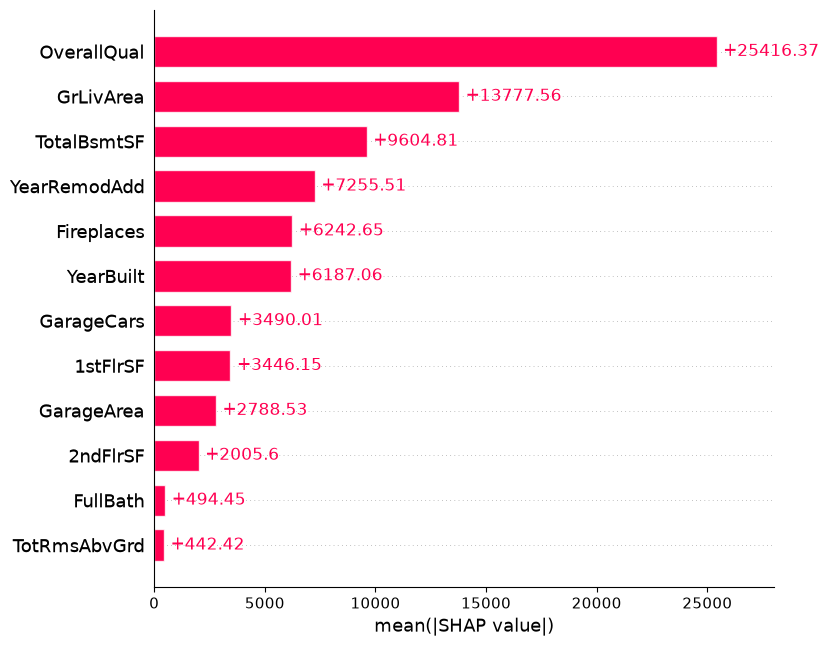

Validation 첫 주택 index : 1411
실제 가격                : 140,000
예측 가격                : 149,904
오차(예측-실제)          : 9,904


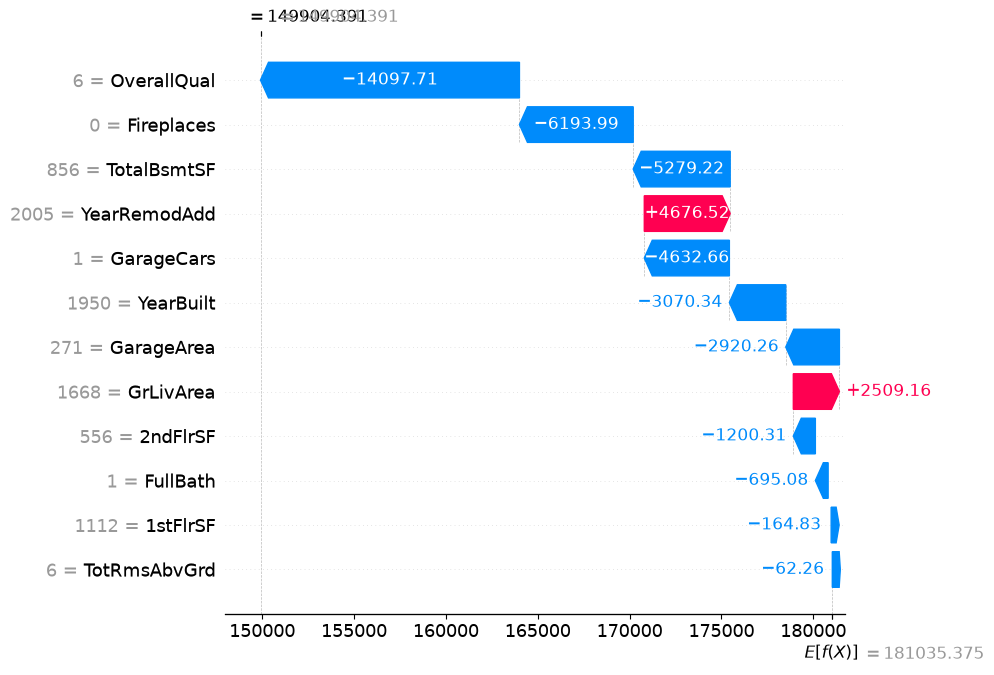

,feature,feature_value,SHAP,abs_SHAP,방향
0,OverallQual,6,-14097.709961,14097.709961,예측 하락(-)
1,Fireplaces,0,-6193.990234,6193.990234,예측 하락(-)
2,TotalBsmtSF,856,-5279.220215,5279.220215,예측 하락(-)
3,YearRemodAdd,2005,4676.520020,4676.520020,예측 상승(+)
4,GarageCars,1,-4632.660156,4632.660156,예측 하락(-)


기준값(base value) : 181,035.38
SHAP 값의 합       : -31,130.98
기준값 + SHAP 합   : 149,904.39
모델 예측값        : 149,904.42
차이               : 0.0312
거의 같은가?       : True


In [24]:
# TODO 2:
explainer = shap.TreeExplainer(xgb_a)
shap_tr = explainer(X_tr)                   
 
importance_comparison = pd.DataFrame({
    "feature": features,
    "FI": xgb_a.feature_importances_,
    "mean_abs_SHAP": np.abs(shap_tr.values).mean(axis=0),
})
importance_comparison["FI_rank"] = (
    importance_comparison["FI"].rank(ascending=False).astype(int)
)
importance_comparison["SHAP_rank"] = (
    importance_comparison["mean_abs_SHAP"].rank(ascending=False).astype(int)
)
importance_comparison["rank_diff(FI-SHAP)"] = (
    importance_comparison["FI_rank"] - importance_comparison["SHAP_rank"]
)
importance_comparison = (
    importance_comparison.sort_values("SHAP_rank").reset_index(drop=True)
)
display(importance_comparison.round(4))
 
shap.plots.bar(shap_tr, max_display=len(features))
 
x0 = X_val.iloc[[0]]
actual0 = y_val.iloc[0]
pred0 = float(xgb_a.predict(x0)[0])
 
print(f"Validation 첫 주택 index : {X_val.index[0]}")
print(f"실제 가격                : {actual0:,.0f}")
print(f"예측 가격                : {pred0:,.0f}")
print(f"오차(예측-실제)          : {pred0 - actual0:,.0f}")
 
sv0 = explainer(x0)
shap.plots.waterfall(sv0[0], max_display=len(features))

local_df = pd.DataFrame({
    "feature": features,
    "feature_value": x0.iloc[0].values,
    "SHAP": sv0.values[0],
})
local_df["abs_SHAP"] = local_df["SHAP"].abs()
local_df["방향"] = np.where(local_df["SHAP"] > 0, "예측 상승(+)", "예측 하락(-)")
local_top5 = (
    local_df.sort_values("abs_SHAP", ascending=False)
    .head(5)
    .reset_index(drop=True)
)
display(local_top5.round(2))

base0 = float(np.ravel(sv0.base_values)[0])
shap_sum = sv0.values[0].sum()
print(f"기준값(base value) : {base0:,.2f}")
print(f"SHAP 값의 합       : {shap_sum:,.2f}")
print(f"기준값 + SHAP 합   : {base0 + shap_sum:,.2f}")
print(f"모델 예측값        : {pred0:,.2f}")
print(f"차이               : {abs(base0 + shap_sum - pred0):.4f}")
print("거의 같은가?       :", np.isclose(base0 + shap_sum, pred0, atol=1.0))

In [25]:
# TODO 3:
top6 = (
    importance_comparison.sort_values("mean_abs_SHAP", ascending=False)
    ["feature"].head(6).tolist()
)
print("선택한 상위 6개 특성:", top6)

xgb_sel = XGBRegressor(
    n_estimators=200, learning_rate=0.05, max_depth=3,
    random_state=42, n_jobs=1,
)
sel_time = fit_timed(xgb_sel, X_tr[top6], y_tr, repeats=3)

def summarize(name, model, cols, fit_time):
    val_pred = model.predict(X_val[cols])
    return {
        "model": name,
        "n_features": len(cols),
        "fit_time(s)": fit_time,
        "Train RMSE": rmse(y_tr, model.predict(X_tr[cols])),
        "Validation RMSE": rmse(y_val, val_pred),
        "Validation R2": r2_score(y_val, val_pred),
    }
 
full_time = model_comparison.loc[
    model_comparison["model"] == "XGBoost (Boosting)", "fit_time(s)"
].iloc[0]
 
feature_comparison = pd.DataFrame([
    summarize("전체 특성 (12개)", xgb_a, features, full_time),
    summarize("SHAP 상위 6개", xgb_sel, top6, sel_time),
])
display(feature_comparison.round(4))
 
base_val = feature_comparison.loc[0, "Validation RMSE"]
sel_val = feature_comparison.loc[1, "Validation RMSE"]
rmse_diff = base_val - sel_val
improve_pct = rmse_diff / base_val * 100
 
print(f"기존 Validation RMSE - 선택 후 Validation RMSE : {rmse_diff:,.2f}")
print(f"기존 대비 개선율                              : {improve_pct:.2f}%")

선택한 상위 6개 특성: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearRemodAdd', 'Fireplaces', 'YearBuilt']


,model,n_features,fit_time(s),Train RMSE,Validation RMSE,Validation R2
0,전체 특성 (12개),12,0.0328,19116.6415,27436.8465,0.8835
1,SHAP 상위 6개,6,0.0224,20282.4803,30029.8571,0.8605


기존 Validation RMSE - 선택 후 Validation RMSE : -2,593.01
기존 대비 개선율                              : -9.45%


## Q5~Q9 답변

- Q5. 전역 SHAP에서 가장 중요한 특성이 특정 주택에서도 반드시 가장 큰 영향을 주나요?
    - 반드시 그렇지 않다. 전역 SHAP는 여러 주택의 |SHAP|를 평균한 값이고, 개별 주택의 기여도는 그 주택의 특성값잉 평균적인 주택과 얼마나 다른지에 따라 달라진다.
    - Validation 첫 주택에서는 전역 1위인 OverallQual이 -14098로 가장 큰 영향을 주어 순위가 일치했으나 나머지 순위는 크게 달랐다.
        - 전역 2위 GrLivArea(평균 |SHAP| 13778)는 이 주택에서 +2509로 12개 중 8번째 순위에 그쳤다.
        - 전역 5위 Fireplaces는 이 주택에서 -6194로 2번째로 큰 영향을 주었다.
    - 따라서 전역 순위는 평균적으로 영향이 큰 특성을 보여줄 뿐이고, 개별 주택의 예측 근거는 지역 SHAP로 확인해야 한다.
- Q6. SHAP 값이 양수/음수라는 것은 각각 무엇을 의미하나요?
    - SHAP 값은 기준값(전체 평균 에측, 181035)에서 출발해 각 특성이 예측을 얼마나 움직였는지를 나타낸다. 양수는 예측값을 높인 방향, 음수는 낮춘 방향이고 절댓값은 그 크기이다.
- Q7: 두 모델 중 무엇을 우선 후보로 선택했나요?
    - XGBoost를 우선 후보로 선택
    - 예측 성능: Validation RMSE는 XGBoost 27437, Random Forest 29318로 XGBoost가 약 1881 낮았다. r2도 0.8835대 0.8670으로 XGBoost가 높았다.
    - 과적합 징후: Random Forest는 Train_sub RMSE가 12368로 매우 낮지만 Validation에서는 29318로 차이가 16950이 된다. 반면 XGBoost는 차이가 8320으로 절반 수준인데, max_depth와 learning rate 둘 다 낮아 Train과 Validation 오차가 더 적게 나온 것으로 볼 수 있다.
    - 학습 시간: 같은 환경에서 n_jobs=1로 3회 측정한 중앙값 기준으로, 이번 실행에서는 XGBoost가 Random Forest보다 약 10배 이상 빨랐다(위 model_comparison 표 참고). 다만 시간은 실행마다 달라지고, RF의 나무가 더 깊게 자라는 등 설정 차이도 영향을 줬을 수 있다. 따라서 일반적인 속도 우열로 단정하지 않는다.
    - 업무 연결: 주택 가격 예측은 오차가 곧 금액 차이로 이어진다. 또한 가격 산정 근거를 고객이나 담당자에게 설명해야 하는 경우가 많기 때문에 오차가 더 작고 일반화 격차가 작으며, SHAP로 예측 근거를 설명할 수 있는 XGBoost가 더 적합하다고 판단했다.
- Q8. Feature Importance와 평균 절댓값 SHAP의 계산 원리와 한계는 무엇이며, 실제 상위 특성 순위는 어떻게 다른가요?
    - Feature Importance
        - 원리: 각 특성이 분할에 쓰였을 때 손실을 얼마나 줄였는지를 학습 과정에서 집계한다.
        - 한계: 방향(상승/하락)을 알 수 없고, 개별 예측을 설명하지 못한다. 몇 번 안 쓰였어도 손실을 크게 줄인 분할이 있으면 높게 나올 수 있다. 상관이 높은 특성끼리는 분할 기회를 나눠 가져 중요도가 왜곡될 수 있다.
    - 평균 절댓값 SHAP
        - 원리: 각 샘플의 예측값과 기준값의 차이를 특성별로 배분한 SHAP 값을 구하고, 그 절댓값을 Train_sub 전체에서 평균한다. 즉, 실제 예측값에 대한 기여 크기를 집계한다.
        - 한계: 평균 절댓값으로 요약하면 방향 정보가 사라진다. 상관된 특성 사이에서 기여가 나뉘는 문제는 여전히 남는다. 또 인과관계가 아니라 모델이 예측에 이 특성을 어떻게 사용했는지에 대한 설명이다.
    - 실제 상위 특성 순위
        - 두 방식 모두 OverallQual이 압도적인 1위였다.
        - 가장 크게 달라진 특성은 GarageCars로, FI는 2위(0.205)였지만 SHAP는 7위(3490)이었다. 
        - YearRemodAdd는 FI 9위/SHAP 4위, TotalBsmtSF는 FI 6위/SHAP 3위이다.
- Q9. 상위 6개 특성은 무엇이며, 선택 전후 RMSE 차이와 개선율을 얼마인가요? 이 시도를 채택할지와 판단의 한계를 설명하세요.
    - 상위 6개 특성은 OverallQual, GrLivArea, TotlaBsmtSF, YearRemodAdd, Fireplaces, YearBuilt이다.
    - 선택 전후 결과는 다음과 같다.
        - Validation RMSE: 27437->30030
            - 차이 = -2593
            - 개선율 = -9.45%(성능 악화)
        - Validation R²: 0.8835 → 0.8605
        - Train RMSE: 19,117 → 20,282
        - fit 시간: 특성을 절반으로 줄이자 학습 시간도 줄었지만(feature_comparison 표 참고), 두 모델 모두 1초 미만이라 실질적인 이득은 작다.
    - 이 시도를 채택하지 않고 12개 특성 모델을 유지한다. Validation 오차가 약 9.5% 커졌고, 시학습 시간은 줄었으나 이 손실을 정당화할 만큼 크지 않다.
    - 판단의 한계
        - 하나의 Train_sub/Validation 분할에서 한 번 비교한 결과
        - 특성 선택에 Train_sub SHAP을 사용했기 때문에, 선택 자체가 이 학습 데이터에 맞춰져 있을 수 있다.
        - 최종 일반화 성능은 학습과 선택에 쓰지 않은 Test 데이터로 따로 평가해야 확인할 수 있다.

---

# 6장 1강 과제. 최종 모델 선정과 hold-out Test 확인

## 배경

세 탐색 전략에서 각각 최적 후보를 얻었습니다.

최종 모델은 **CV 평균을 우선 기준으로 비교**하되, 성능 차이가 매우 작다면 다음 항목도 함께 확인합니다.

- CV 표준편차
- 탐색 시간

그리고 최종 후보를 정한 뒤 **hold-out Test는 딱 한 번만** 사용합니다.

> 탐색 시간은 각 탐색 도구의 내부 동작과 실행 환경에 따라 포함되는 작업이 조금 다를 수 있으므로, 이번 실습에서는 절대적인 속도 순위가 아니라 **대략적인 탐색 비용 비교**로 해석합니다.

## 요구사항

1. Grid / Random / Optuna 결과를 다음 컬럼으로 하나의 DataFrame에 정리합니다.
   - `search_method`
   - `best_params`
   - `cv_mean`
   - `cv_std`
   - `search_seconds`
2. 세 후보를 비교합니다.
3. CV 평균을 우선 기준으로 최종 후보를 선택하고, 평균이 거의 비슷하다면 CV 표준편차와 탐색 비용도 함께 고려하여 선택 이유를 설명합니다.
4. 튜닝하지 않은 기준 모델(`RandomForestRegressor(n_estimators=100, max_depth=None, random_state=42, n_jobs=-1)`)과 3번에서 선택한 튜닝 후보를 비교하세요. 필수 실습의 `cv=5`와 동일한 `KFold(n_splits=5, shuffle=False)` 분할을 두 모델에 공통 적용하고, `cross_validate(..., scoring="r2", return_train_score=True)`로 평가하세요.
   - Fold별 Train R²와 검증 R²를 `fold_comparison`으로 정리합니다.
   - Train R² 평균, 검증 R² 평균·표준편차, `Train 평균 - 검증 평균`을 `tuning_comparison`으로 정리합니다.
   - `튜닝 후 CV 평균 R² - 기준 모델 CV 평균 R²`를 계산합니다. R² 차이값으로 보고하며, 백분율 개선율로 바꾸지 않습니다.
   - 평균·변동·Train–검증 차이로 개선 여부를 설명합니다. 튜닝이 개선되지 않았다면 기준 모델 유지도 가능합니다. Test 확인 전에 최종 모델과 선택 이유를 확정합니다.
   - 최종 선택 모델을 Train 전체에 다시 학습합니다.
5. hold-out Test에서 `.score()`로 최종 R²를 딱 한 번 확인합니다.
6. 최종 선택 모델의 CV 평균과 hold-out Test R²의 차이를 계산하고, 과적합 가능성과 일반화 판단의 한계를 설명합니다. Test 결과를 본 뒤 다시 튜닝하거나 후보를 교체하지 않습니다.
7. 선택한 모델을 `model_artifacts/best_model.pkl`로 저장합니다.
8. 다음 정보를 `model_artifacts/model_meta.json`에 저장합니다.
   - 모델 이름
   - 저장 시각
   - 선택한 탐색 방법
   - 최적 파라미터
   - CV 평균
   - CV 표준편차
   - 최종 Test R²
   - 기준 모델 설정, 튜닝 후보 설정·탐색 방법
   - 튜닝 전후 CV 비교 결과와 CV 평균 R² 차이
   - 선택 모델 CV 평균과 Test R²의 차이

### 확인 포인트

- Test 데이터를 탐색 중간에 사용하지 않았는가?
- CV 평균을 우선으로 보고, 필요할 때 표준편차와 탐색 시간도 함께 고려했는가?
- 최종 모델을 정한 뒤 Test를 한 번만 확인했는가?
- 모델뿐 아니라 메타데이터도 저장했는가?

- 튜닝 전후를 동일한 Fold에서 비교하고 개선 여부를 수치로 설명했는가?
- CV의 `test_score`는 Fold 내부 검증 점수이며 hold-out Test 점수가 아님을 구분했는가?
- 작은 표준편차나 CV/Test 점수의 일치만으로 일반화가 보장된다고 단정하지 않았는가?

In [26]:
# 실습 준비 코드

import os
import json
import time
import joblib
import optuna
import numpy as np
import pandas as pd

from datetime import datetime
from scipy.stats import randint

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    cross_val_score,
    cross_validate,
    KFold,
)
from sklearn.ensemble import RandomForestRegressor

optuna.logging.set_verbosity(optuna.logging.WARNING)  

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual", "GrLivArea", "GarageCars", "GarageArea",
    "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "FullBath",
    "TotRmsAbvGrd", "YearBuilt", "YearRemodAdd", "Fireplaces",
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train 크기:", X_train.shape)
print("Hold-out Test 크기:", X_test.shape)

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    {"n_estimators": [100, 200, 300], "max_depth": [4, 8, 12]},
    cv=5,
    scoring="r2",
)
start = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_seconds = time.perf_counter() - start

random_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions={
        "n_estimators": randint(100, 301),
        "max_depth": randint(4, 13),
    },
    n_iter=9,
    cv=5,
    scoring="r2",
    random_state=42,
)
start = time.perf_counter()
random_search.fit(X_train, y_train)
random_seconds = time.perf_counter() - start

def objective(trial):
    model = RandomForestRegressor(
        n_estimators=trial.suggest_int("n_estimators", 100, 300),
        max_depth=trial.suggest_int("max_depth", 4, 12),
        random_state=42,
        n_jobs=-1,
    )
    return cross_val_score(model, X_train, y_train, cv=5, scoring="r2").mean()


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=3),
)
start = time.perf_counter()
study.optimize(objective, n_trials=9)
optuna_seconds = time.perf_counter() - start

optuna_best_scores = cross_val_score(
    RandomForestRegressor(**study.best_params, random_state=42, n_jobs=-1),
    X_train, y_train, cv=5, scoring="r2",
)

print(f"\nGrid   : {grid_search.best_params_}  {grid_search.best_score_:.4f}  ({grid_seconds:.2f}s)")
print(f"Random : {random_search.best_params_}  {random_search.best_score_:.4f}  ({random_seconds:.2f}s)")
print(f"Optuna : {study.best_params}  {study.best_value:.4f}  ({optuna_seconds:.2f}s)")


def to_py(obj):
    if isinstance(obj, dict):
        return {k: to_py(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [to_py(v) for v in obj]
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    return obj

Train 크기: (1168, 12)
Hold-out Test 크기: (292, 12)

Grid   : {'max_depth': 12, 'n_estimators': 200}  0.8206  (8.13s)
Random : {'max_depth': 11, 'n_estimators': 230}  0.8210  (8.10s)
Optuna : {'n_estimators': 175, 'max_depth': 12}  0.8213  (7.83s)


In [27]:
#TODO
def best_row(search):
    """GridSearchCV / RandomizedSearchCV의 최적 조합 CV 평균·표준편차"""
    i = search.best_index_
    return (
        search.cv_results_["mean_test_score"][i],
        search.cv_results_["std_test_score"][i],
    )

grid_mean, grid_std = best_row(grid_search)
rand_mean, rand_std = best_row(random_search)

search_comparison = pd.DataFrame([
    {"search_method": "GridSearchCV", "best_params": to_py(grid_search.best_params_),
     "cv_mean": grid_mean, "cv_std": grid_std, "search_seconds": grid_seconds},
    {"search_method": "RandomizedSearchCV", "best_params": to_py(random_search.best_params_),
     "cv_mean": rand_mean, "cv_std": rand_std, "search_seconds": random_seconds},
    {"search_method": "Optuna (TPE)", "best_params": to_py(study.best_params),
     "cv_mean": optuna_best_scores.mean(), "cv_std": optuna_best_scores.std(),
     "search_seconds": optuna_seconds},
])
search_comparison["mean_gap_from_best"] = (
    search_comparison["cv_mean"].max() - search_comparison["cv_mean"]
)
display(search_comparison.round(4))

TIE_TOL = 0.001

near_best = search_comparison[search_comparison["mean_gap_from_best"] <= TIE_TOL]
selected_search = near_best.sort_values(["cv_std", "search_seconds"]).iloc[0]

print(f"평균이 거의 같은 후보(차이 ≤ {TIE_TOL}):", near_best["search_method"].tolist())
print("선택한 튜닝 후보:", selected_search["search_method"], selected_search["best_params"])

kf = KFold(n_splits=5, shuffle=False)

base_params = {"n_estimators": 100, "max_depth": None}
tuned_params = selected_search["best_params"]

candidates = {
    "기준 모델 (튜닝 전)": RandomForestRegressor(**base_params, random_state=42, n_jobs=-1),
    f"튜닝 후보 ({selected_search['search_method']})":
        RandomForestRegressor(**tuned_params, random_state=42, n_jobs=-1),
}

cv_out = {
    name: cross_validate(m, X_train, y_train, cv=kf, scoring="r2", return_train_score=True)
    for name, m in candidates.items()
}


fold_comparison = pd.DataFrame({"fold": range(1, 6)})
for name, res in cv_out.items():
    fold_comparison[f"{name} Train R2"] = res["train_score"]
    fold_comparison[f"{name} 검증 R2"] = res["test_score"]
display(fold_comparison.round(4))

tuning_comparison = pd.DataFrame([
    {
        "model": name,
        "Train R2 평균": res["train_score"].mean(),
        "검증 R2 평균": res["test_score"].mean(),
        "검증 R2 표준편차": res["test_score"].std(),
        "Train 평균 - 검증 평균": res["train_score"].mean() - res["test_score"].mean(),
    }
    for name, res in cv_out.items()
])
display(tuning_comparison.round(4))

base_name, tuned_name = list(cv_out.keys())
base_cv_mean = cv_out[base_name]["test_score"].mean()
tuned_cv_mean = cv_out[tuned_name]["test_score"].mean()
r2_diff = tuned_cv_mean - base_cv_mean
print(f"튜닝 후 CV 평균 R² - 기준 모델 CV 평균 R² = {r2_diff:+.4f}")

if r2_diff > 0:
    final_name, final_params = tuned_name, tuned_params
    final_method = selected_search["search_method"]
else:
    final_name, final_params = base_name, base_params
    final_method = "튜닝 없음 (기준 모델 유지)"

final_cv_mean = cv_out[final_name]["test_score"].mean()
final_cv_std = cv_out[final_name]["test_score"].std()
print("최종 선택 모델:", final_name, final_params)

final_model = RandomForestRegressor(**final_params, random_state=42, n_jobs=-1)
final_model.fit(X_train, y_train)

test_r2 = final_model.score(X_test, y_test)
cv_test_gap = final_cv_mean - test_r2

print(f"최종 모델 CV 평균 R²   : {final_cv_mean:.4f} (± {final_cv_std:.4f})")
print(f"hold-out Test R²       : {test_r2:.4f}")
print(f"CV 평균 - Test R²      : {cv_test_gap:+.4f}")

os.makedirs("model_artifacts", exist_ok=True)

model_path = "model_artifacts/best_model.pkl"
joblib.dump(final_model, model_path)

model_meta = to_py({
    "model_name": "RandomForestRegressor",
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "selected_search_method": final_method,
    "best_params": final_params,
    "cv_mean_r2": final_cv_mean,
    "cv_std_r2": final_cv_std,
    "test_r2": test_r2,
    "baseline_model": {
        "params": base_params,
        "random_state": 42,
    },
    "tuned_candidate": {
        "search_method": selected_search["search_method"],
        "params": tuned_params,
    },
    "tuning_cv_comparison": {
        "cv": "KFold(n_splits=5, shuffle=False)",
        "summary": tuning_comparison.to_dict(orient="records"),
        "tuned_minus_base_cv_mean_r2": r2_diff,
    },
    "cv_mean_minus_test_r2": cv_test_gap,
    "features": features,
    "search_comparison": search_comparison.drop(columns="mean_gap_from_best")
                                          .to_dict(orient="records"),
})

with open("model_artifacts/model_meta.json", "w", encoding="utf-8") as f:
    json.dump(model_meta, f, ensure_ascii=False, indent=2)

print("저장 완료:", os.listdir("model_artifacts"))

loaded = joblib.load(model_path)
sample = X_train.head(5)
print("불러온 모델 예측 일치:", np.allclose(loaded.predict(sample), final_model.predict(sample)))

,search_method,best_params,cv_mean,cv_std,search_seconds,mean_gap_from_best
0,GridSearchCV,"{'max_depth': 12, 'n_estimators': 200}",0.8206,0.0644,8.1346,0.0006
1,RandomizedSearchCV,"{'max_depth': 11, 'n_estimators': 230}",0.8210,0.0651,8.1018,0.0002
2,Optuna (TPE),"{'n_estimators': 175, 'max_depth': 12}",0.8213,0.0643,7.8304,0.0000


평균이 거의 같은 후보(차이 ≤ 0.001): ['GridSearchCV', 'RandomizedSearchCV', 'Optuna (TPE)']
선택한 튜닝 후보: Optuna (TPE) {'n_estimators': 175, 'max_depth': 12}


,fold,기준 모델 (튜닝 전) Train R2,기준 모델 (튜닝 전) 검증 R2,튜닝 후보 (Optuna (TPE)) Train R2,튜닝 후보 (Optuna (TPE)) 검증 R2
0,1,0.9717,0.8627,0.9715,0.8694
1,2,0.9754,0.6808,0.9764,0.6967
2,3,0.9750,0.8343,0.9721,0.8280
3,4,0.9746,0.8450,0.9726,0.8428
4,5,0.9717,0.8723,0.9709,0.8694


,model,Train R2 평균,검증 R2 평균,검증 R2 표준편차,Train 평균 - 검증 평균
0,기준 모델 (튜닝 전),0.9737,0.8190,0.0704,0.1547
1,튜닝 후보 (Optuna (TPE)),0.9727,0.8213,0.0643,0.1514


튜닝 후 CV 평균 R² - 기준 모델 CV 평균 R² = +0.0022
최종 선택 모델: 튜닝 후보 (Optuna (TPE)) {'n_estimators': 175, 'max_depth': 12}
최종 모델 CV 평균 R²   : 0.8213 (± 0.0643)
hold-out Test R²       : 0.8911
CV 평균 - Test R²      : -0.0698
저장 완료: ['best_model.pkl', 'model_meta.json']
불러온 모델 예측 일치: True


### Q4. CV 평균이 아주 조금 높은 모델의 탐색 시간이 몇 배 더 길다면 무조건 그 모델을 선택해야 하나요?

**답변:**  
- 아니요. CV 평균은 5개 Fold 점수의 평균이라 그 자체로도 흔들림이 있다. 이런 경우 표준편차, 탐색비용, 운영 비용까지 함께 고려해야 한다.

| 탐색 방법 | 최적 파라미터 | CV 평균 | CV 표준편차 |
| --- | --- | --- | --- |
| GridSearchCV | max_depth=12, n_estimators=200 | 0.8206 | 0.0644 |
| RandomizedSearchCV | max_depth=11, n_estimators=230 | 0.8210 | 0.0651 |
| Optuna(TPE) | max_depth=12, n_estimators=175 | 0.8213 | 0.0643 |
- 세 후보의 CV 평균 차이는 최대 0.0007이다. 
- 세 방법 모두 깊이 11~12의 비슷한 영역을 찾았다.
- Optuna가 평균이 가장 높으면서 표준편차도 가장 작고, 탐색 시간도 가장 짧았다. 그래서 따져야 할 트레이드오프 없이 Optuna 후보를 선택했다.
- 탐색 시간은 search_comparison 표 기준으로 세 방법 모두 비슷한 수준이었다(가장 느린 방법도 가장 빠른 방법의 1.3배 이내). 이번 실행에서는 Optuna가 가장 짧았지만, 시간은 실행 환경에 따라 달라지므로 대략적인 비용 비교로만 해석했다.

### Q5. hold-out Test를 탐색 마지막에 한 번만 사용해야 하는 이유는 무엇인가요?

**답변:**  
- hold-out Test는 학습과 모델 선택에 전혀 쓰이지 않았을 때만 처음 보는 데이터에 대한 성능을 공정하게 추정할 수 있다. 탐색 중간에 Test 점수를 보고 하이퍼파라미터나 모델을 바꾸면 선택 과정이 Test에 맞춰져, 최종 Test 점수가 실제 일반화 성능보다 낙관적으로 나온다. 따라서 모든 탐색과 선택은 Train 내부의 교차검증으로 마치고, 최종 모델을 확정한 뒤 Test는 한 번만 사용한다.

### Q6. 튜닝 전후 CV 평균 R²는 얼마나 달라졌나요? Fold별 변동과 Train–검증 점수 차이를 근거로 개선 여부를 설명하세요.

**답변:**
- 동일한 KFold 분할에서 비교한 결과

|  | 기준 모델(n_estimators=100, max_depth=None) | 튜닝 후보(Optuna, n_estimators=175, max_depth=12) | 
| --- | --- | --- |
| Train r2 평균 | 0.9737 | 0.9727 |
| 검증 r2 평균 | 0.8190 | 0.8213 | 
| 검증 r2 표준편차 | 0.0704 | 0.0643 | 
| Train 평균-검증 평균 | 0.1547 | 0.1514 | 
- CV 평균 r2 차이 (튜닝 후 - 기준) = +0.0022
- Fold별 변동: 튜닝 후보가 더 높았던 Fold는 5개 중 2개 뿐이었다.
- Train-검증 차이 : 0.1547에서 0.1514로 0.0033 줄어 거의 같다. max_depth=12는 이 데이터에서 나무를 크게 제한하지 않는 수준이라, Train r2가 여전히 0.97대이고 과적합 경향도 기준 모델과 비슷하게 남아있다.
- 판단: 평균이 오르고 변동과 Trian-검증 차이가 줄었으므로, 결과를 보기 전에 정한 규칙(r2 차이>0)에 따라 튜닝 후보를 채택했다. 다만 개선 폭 0.0022는 CV 표준편차(약 0.064)에 비해 매우 작고, 5개 Fold 중 3개에서는 오히려 약간 낮았다. 

### Q7. CV 결과와 최종 Test 결과를 어떻게 해석했나요? 과적합 가능성과 일반화 판단의 한계를 설명하세요.

**답변:**
- 최종 모델의 CV 평균 r2는 0.8213, hold-out Test R²는 0.8911로, CV − Test = −0.0698이다. 

    - 과적합 판단: Test 점수가 CV 추정보다 떨어지지 않았으므로, 튜닝 과정이 Train 분할에 과하게 맞춰졌다는 징후는 보이지 않는다. 하지만 모델 자체는 Train r2가 0.97대로 검증 r2보다 약 0.15 높다. 
    - Test가 더 높은 이유: 차이(0.0698)는 CV 표준편차(0.0643)와 비슷한 크기로, Fold 간 흔들림 범위를 약간 넘는 정도이다. CV에는 검증 r2가 0.70 미만인 어려운 Fold 2가 포함되어 평균을 끌어내렸다.
    - 일반화 판단의 한계
        - Test 0.8911은 한 번의 무작위 분할에서 나온 하나의 점수이다. 새 데이터에서의 기대 성능은 Test 점수보다 CV 평균(0.82 안팎)과 Fold 범위(약 0.70~0.87)를 함께 보고 보수적으로 판단하는 것이 안전하다.
        - CV 표준편차가 작거나 CV와 Test가 비슷하다고 해서 일반화가 보장되지는 않는다. 이번처럼 Test가 더 높다고 해서 모델이 더 좋다는 뜻도 아니다.
        - 시기나 지역 등 데이터 분포가 바뀌면 성능이 달라질 수 있다. R²만으로는 가격대별 오차 크기도 알 수 없다.